# LAB 12 — Stage 06: Evidence-Based Data Preprocessing, Controlled Experiments & Pipeline Selection

**Scope:** Bu notebook'un amacı `SimpleImputer`/`OneHotEncoder`/`RobustScaler` gibi araçları
kullanmak değildir -- amaç, preprocessing kararlarının veri özellikleri, matematiksel
gerekçeler, **kontrollü deneyler** ve **leakage-safe Cross-Validation** sonuçlarıyla
desteklenmesini sağlamaktır.

## Mandatory Engineering Workflow

**Engineering Question → Hypothesis → Statistical Evidence → Controlled Experiment →
Comparative Results → Engineering Decision → Reproducibility**

## Critical Scientific Principle

İyi bir preprocessing kararı 8 bileşenden oluşur: Business Semantics, Data Contract,
Statistical Diagnostics, Prediction-Time Availability, Controlled Comparisons, Generalization
Evidence, Operational Complexity, Reproducibility. **Çok küçük performans farkları kesin
üstünlük olarak sunulmayacaktır.**

## Important Exception (Restriction 26)

Bu notebook'ta Ridge ve Random Forest gibi sabit **probe estimator'lar** eğitilmesine izin
vardır -- bunlar **yalnızca preprocessing alternatiflerini karşılaştırmak içindir**, Stage 08
(Baseline) veya Stage 09 (Model Benchmarking)'in yerine geçmez.

In [1]:
# Same environment setup pattern as LAB02-LAB12 Stage 01-05.
import sys
import json
import hashlib
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler, MinMaxScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import BaseEstimator, TransformerMixin

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config  # noqa: E402

config = load_config()
lab12_cfg = config["lab12"]
stage06_cfg = lab12_cfg["stage06"]
RANDOM_SEED = config["random_seed"]
np.random.seed(RANDOM_SEED)
print("Project root:", PROJECT_ROOT)
print("stage06 config loaded:", list(stage06_cfg.keys()))

Project root: /app
stage06 config loaded: ['enabled', 'evaluation', 'probe_models', 'experiments', 'feature_policy', 'reproducibility', 'artifacts']


---

## Section 02 — Stage 05 Protocol Recovery

### Critical Rule -- EXP-ID Reconciliation

Stage 04'ün **iki farklı** deney tanımı bulunuyor: `stage04_statistical_evidence.csv`'deki
eski Experiment Matrix (EXP-01=Target Transform, EXP-02=Scaling, EXP-03=Weight Inclusion,
EXP-04=Rare Category Grouping, EXP-05=Outlier Capping) ile
`stage06_preprocessing_experiment_plan.md`'nin candidate bölümleri (Missing Value → Encoding →
Scaling → Outlier → Target Transformation sırası). **Bu notebook, ikincisini (güncel plan
dokümanını) esas almaktadır** -- bu nedenle burada: **EXP-01=Missing Value, EXP-02=Encoding,
EXP-03=Scaling, EXP-04=Outlier Treatment, EXP-05=Target Transformation.** "Weight Inclusion"
ayrı bir EXP değil, EXP-01'in bir sensitivity alt-dalı olarak ele alınmaktadır (D-006).

In [2]:
ARTIFACT_DIR = PROJECT_ROOT / lab12_cfg["artifacts"]["directory"]

with open(ARTIFACT_DIR / "dataset_profile.json", encoding="utf-8") as f:
    stage03_profile = json.load(f)
with open(ARTIFACT_DIR / "stage05_protocol_fingerprint.json", encoding="utf-8") as f:
    stage05_fingerprint = json.load(f)
with open(ARTIFACT_DIR / "stage05_split_metadata.json", encoding="utf-8") as f:
    stage05_split_metadata = json.load(f)

cv_fold_summary_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_summary.csv")
cv_fold_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_cv_fold_manifest.csv")
split_manifest_s05 = pd.read_csv(ARTIFACT_DIR / "stage05_split_manifest.csv")

print("Stage 05 protocol fingerprint:", stage05_fingerprint["protocol_fingerprint_sha256"])
print("Population counts (Stage 05):", stage05_split_metadata["population_counts"])
print("\nFrozen CV fold summary:")
cv_fold_summary_s05

Stage 05 protocol fingerprint: b87ca0fde5fd9ddef45f191a0bb1c3e4e2a014b9c9641be5e8d20bb2458935e7
Population counts (Stage 05): {'Train': 5551, 'Validation': 910, 'Protected_Test': 569}

Frozen CV fold summary:


,Fold_ID,Train_Start,Train_End,CV_Validation_Start,CV_Validation_End,Train_Shipments,CV_Validation_Shipments,Gap_Days,Group_Overlap_Count,Eligible_Train_Labels,Eligible_CV_Validation_Labels,Status
0,1,2006-05-02,2009-12-31,2010-01-01,2010-12-31,2028,932,0,0,1735,780,Feasible
1,2,2006-05-02,2010-12-31,2011-01-01,2011-12-31,2960,823,0,0,2515,776,Feasible
2,3,2006-05-02,2011-12-31,2012-01-01,2012-12-31,3783,898,0,0,3291,861,Feasible
3,4,2006-05-02,2012-12-31,2013-01-01,2013-12-31,4681,870,0,0,4152,835,Feasible


### Dataset Integrity Re-Verification

In [3]:
dataset_dir = PROJECT_ROOT / lab12_cfg["dataset"]["directory"]
candidates_files = sorted(dataset_dir.glob(lab12_cfg["dataset"]["filename_pattern"]))
assert len(candidates_files) == 1
DATASET_PATH = candidates_files[0]
ENCODING = lab12_cfg["dataset"]["encoding"]
TARGET_COLUMN = lab12_cfg["dataset"]["target_column"]
PRIMARY_KEY = "ASN/DN #"


def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


current_hash = calculate_file_hash(DATASET_PATH)
assert current_hash == stage03_profile["SHA256"] == stage05_fingerprint["fingerprint_components"]["dataset_sha256"]
print("Dataset hash verified unchanged across Stage 01-03 -> Stage 05 -> Stage 06:", current_hash)

# Recompute the Stage 05 fingerprint from scratch and confirm it matches -- any mismatch
# would mean the frozen protocol was altered, which must halt experimentation (Section 2 rule).
def compute_protocol_fingerprint(components: dict) -> str:
    canonical_json = json.dumps(components, sort_keys=True, separators=(",", ":"), default=str)
    return hashlib.sha256(canonical_json.encode("utf-8")).hexdigest()


recomputed_fingerprint = compute_protocol_fingerprint(stage05_fingerprint["fingerprint_components"])
assert recomputed_fingerprint == stage05_fingerprint["protocol_fingerprint_sha256"]
print("Stage 05 protocol fingerprint recomputed and matches: OK -- frozen protocol is intact, proceeding.")

Dataset hash verified unchanged across Stage 01-03 -> Stage 05 -> Stage 06: 9cffdb4ab8c6135b0f999c91b3a5c6e88a3c3dfc28c7c85feb9e97f986e3578a
Stage 05 protocol fingerprint recomputed and matches: OK -- frozen protocol is intact, proceeding.


---

## Section 03 — Feature Schema & Eligibility

Stage 07'de kapsamlı Feature Engineering yapılacaktır -- bu notebook'ta **yeni interaction
feature, target encoding veya SHAP-based selection uygulanmamaktadır.** Yalnızca onaylanmış,
mevcut shipment-level feature'lar kullanılır.

In [4]:
df = pd.read_csv(DATASET_PATH, encoding=ENCODING)
fc_numeric = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
df["_fc_is_numeric"] = fc_numeric.notna()
df["_fc_numeric"] = fc_numeric
df["_wt_numeric"] = pd.to_numeric(df["Weight (Kilograms)"], errors="coerce")
df["_sched_date"] = pd.to_datetime(df["Scheduled Delivery Date"], errors="coerce", format="mixed")

shipment_view = df.groupby(PRIMARY_KEY).agg(
    Shipment_Mode=("Shipment Mode", "first"), INCO_Term=("Vendor INCO Term", "first"),
    Country=("Country", "first"), Product_Group=("Product Group", "first"),
    Line_Item_Qty_Sum=("Line Item Quantity", "sum"), Line_Item_Value_Sum=("Line Item Value", "sum"),
    Weight_KG=("_wt_numeric", "max"), Sched_Date=("_sched_date", "min"),
    Has_Numeric_Target=("_fc_is_numeric", "any"),
    Freight_Cost_USD=("_fc_numeric", lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan),
).reset_index()
print("Shipment-level modeling view shape:", shipment_view.shape)

Shipment-level modeling view shape: (7030, 11)


In [5]:
feature_allowlist = pd.DataFrame([
    {"Feature": "Shipment_Mode", "Semantic_Type": "Categorical Nominal", "Prediction_Time_Availability": "Conditionally Available", "Missing_Rate_Pct": round(shipment_view["Shipment_Mode"].isna().mean()*100, 2), "Cardinality": shipment_view["Shipment_Mode"].nunique(), "Leakage_Risk": "None", "Inclusion_Decision": "Confirmed Available -- main feature set"},
    {"Feature": "INCO_Term", "Semantic_Type": "Categorical Nominal", "Prediction_Time_Availability": "Available", "Missing_Rate_Pct": round(shipment_view["INCO_Term"].isna().mean()*100, 2), "Cardinality": shipment_view["INCO_Term"].nunique(), "Leakage_Risk": "None (selection-bias risk tracked separately, Stage 03.5/04)", "Inclusion_Decision": "Confirmed Available -- main feature set"},
    {"Feature": "Country", "Semantic_Type": "Categorical Nominal", "Prediction_Time_Availability": "Available", "Missing_Rate_Pct": round(shipment_view["Country"].isna().mean()*100, 2), "Cardinality": shipment_view["Country"].nunique(), "Leakage_Risk": "None", "Inclusion_Decision": "Confirmed Available -- main feature set"},
    {"Feature": "Product_Group", "Semantic_Type": "Categorical Nominal", "Prediction_Time_Availability": "Available", "Missing_Rate_Pct": round(shipment_view["Product_Group"].isna().mean()*100, 2), "Cardinality": shipment_view["Product_Group"].nunique(), "Leakage_Risk": "None", "Inclusion_Decision": "Confirmed Available -- main feature set"},
    {"Feature": "Line_Item_Qty_Sum", "Semantic_Type": "Numeric", "Prediction_Time_Availability": "Conditionally Available (D-010 Pending)", "Missing_Rate_Pct": round(shipment_view["Line_Item_Qty_Sum"].isna().mean()*100, 2), "Cardinality": None, "Leakage_Risk": "None", "Inclusion_Decision": "Conditionally Available -- main feature set"},
    {"Feature": "Line_Item_Value_Sum", "Semantic_Type": "Numeric", "Prediction_Time_Availability": "Conditionally Available (D-010 Pending)", "Missing_Rate_Pct": round(shipment_view["Line_Item_Value_Sum"].isna().mean()*100, 2), "Cardinality": None, "Leakage_Risk": "None", "Inclusion_Decision": "Conditionally Available -- main feature set"},
    {"Feature": "Weight_KG", "Semantic_Type": "Numeric", "Prediction_Time_Availability": "Unknown (D-006)", "Missing_Rate_Pct": round(shipment_view["Weight_KG"].isna().mean()*100, 2), "Cardinality": None, "Leakage_Risk": "None (correlation != availability)", "Inclusion_Decision": "EXCLUDED from main set -- sensitivity-only (D-006)"},
    {"Feature": "Scheduled Delivery Date (calendar parts)", "Semantic_Type": "Date", "Prediction_Time_Availability": "Conditional (D-007)", "Missing_Rate_Pct": 0.0, "Cardinality": None, "Leakage_Risk": "None -- but used for splitting, not yet as a feature", "Inclusion_Decision": "Deferred to Stage 07"},
    {"Feature": "Freight Cost (USD)", "Semantic_Type": "Target", "Prediction_Time_Availability": "N/A (target)", "Missing_Rate_Pct": None, "Cardinality": None, "Leakage_Risk": "N/A", "Inclusion_Decision": "TARGET -- never a model input"},
])
feature_allowlist

,Feature,Semantic_Type,Prediction_Time_Availability,Missing_Rate_Pct,Cardinality,Leakage_Risk,Inclusion_Decision
0,Shipment_Mode,Categorical Nominal,Conditionally Available,3.21,4.0,None,Confirmed Available -- main feature set
1,INCO_Term,Categorical Nominal,Available,0.00,8.0,"None (selection-bias risk tracked separately, ...",Confirmed Available -- main feature set
2,Country,Categorical Nominal,Available,0.00,43.0,None,Confirmed Available -- main feature set
3,Product_Group,Categorical Nominal,Available,0.00,5.0,None,Confirmed Available -- main feature set
4,Line_Item_Qty_Sum,Numeric,Conditionally Available (D-010 Pending),0.00,NaN,None,Conditionally Available -- main feature set
5,Line_Item_Value_Sum,Numeric,Conditionally Available (D-010 Pending),0.00,NaN,None,Conditionally Available -- main feature set
6,Weight_KG,Numeric,Unknown (D-006),9.36,NaN,None (correlation != availability),EXCLUDED from main set -- sensitivity-only (D-...
7,Scheduled Delivery Date (calendar parts),Date,Conditional (D-007),0.00,NaN,"None -- but used for splitting, not yet as a f...",Deferred to Stage 07
8,Freight Cost (USD),Target,N/A (target),NaN,NaN,N/A,TARGET -- never a model input


### Critical Feature Restrictions (Verified)

`Freight Cost (USD)`, target-derived oranlar, raw record identifier'ları (`ASN/DN #`), reference
string'leri, anchor-resolution label'ları ve post-shipment actual field'ları (`Delivered to
Client Date`/`Delivery Recorded Date`) **model input'u olarak kullanılmamıştır** -- yukarıdaki
allowlist bunu açıkça göstermektedir.

### Required Visualization

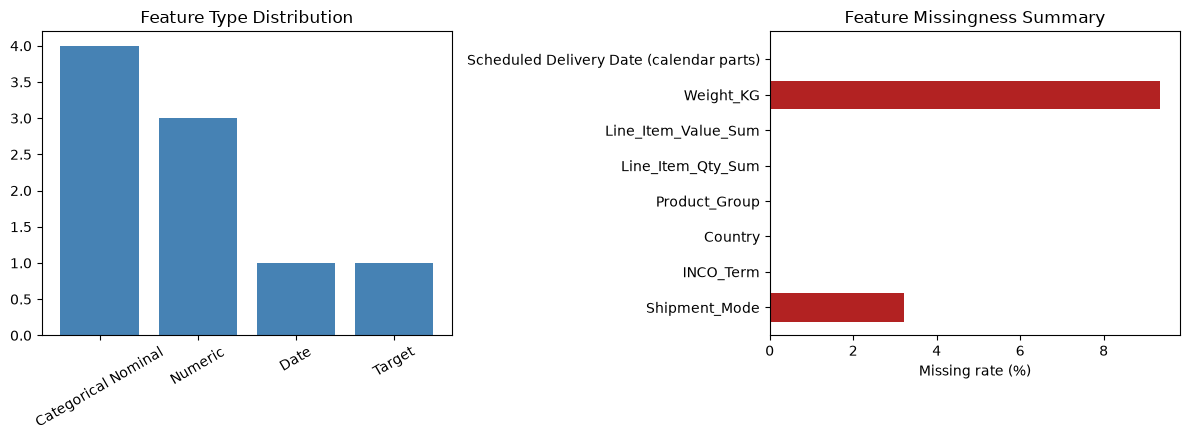

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
type_counts = feature_allowlist["Semantic_Type"].value_counts()
axes[0].bar(type_counts.index, type_counts.values, color="steelblue")
axes[0].set_title("Feature Type Distribution")
axes[0].tick_params(axis="x", rotation=30)

missing_rates = feature_allowlist.dropna(subset=["Missing_Rate_Pct"])
axes[1].barh(missing_rates["Feature"], missing_rates["Missing_Rate_Pct"], color="firebrick")
axes[1].set_title("Feature Missingness Summary")
axes[1].set_xlabel("Missing rate (%)")
plt.tight_layout()
plt.show()

### Engineering Decision

Bu aşamada yalnızca **deneylerde kullanılacak geçerli feature schema** kabul edilmiştir --
nihai preprocessing yöntemi seçilmemiştir.

`NUMERIC_FEATURES = [Line_Item_Qty_Sum, Line_Item_Value_Sum]`,
`CATEGORICAL_FEATURES = [Shipment_Mode, INCO_Term, Country, Product_Group]` ana probe feature
set'idir; `Weight_KG` yalnızca ayrı bir sensitivity deneyinde kullanılacaktır.

In [7]:
NUMERIC_FEATURES = ["Line_Item_Qty_Sum", "Line_Item_Value_Sum"]
CATEGORICAL_FEATURES = ["Shipment_Mode", "INCO_Term", "Country", "Product_Group"]
ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
print("Main probe feature set:", ALL_FEATURES)

Main probe feature set: ['Line_Item_Qty_Sum', 'Line_Item_Value_Sum', 'Shipment_Mode', 'INCO_Term', 'Country', 'Product_Group']


---

## Section 04 — Pipeline & ColumnTransformer Architecture, Probe Estimator Design

### Forbidden vs Required

**Forbidden (yalnızca eğitsel karşı-örnek):**
```python
X_scaled = scaler.fit_transform(X_all)  # INCORRECT -- global fit
```

**Required:** `Pipeline` + `ColumnTransformer`, her fold'un **kendi training verisine** fit
edilir.

### Probe Estimators

**Probe A — Ridge** (`alpha=10.0`, numeric scaling'e duyarlı, yorumlanabilir linear kontrol).
**Probe B — Random Forest** (`n_estimators=80, max_depth=8, min_samples_leaf=3`, nonlinear,
scaling'e daha az duyarlı). Hyperparameter'lar deney performansına göre **optimize
edilmemiştir** -- config'ten sabit okunur.

In [8]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    # Learns per-column lower/upper quantile bounds from the data it is FIT on (always the
    # fold training data within a Pipeline) -- transform() clips any input to those bounds.
    # Deterministic, cloneable, sklearn-compatible (fit/transform API).
    def __init__(self, lower_q=0.01, upper_q=0.99):
        self.lower_q = lower_q
        self.upper_q = upper_q

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.quantile(X, self.lower_q, axis=0)
        self.upper_bounds_ = np.quantile(X, self.upper_q, axis=0)
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return np.clip(X, self.lower_bounds_, self.upper_bounds_)


def build_preprocessor(numeric_impute="median", add_missing_indicator=False, numeric_scaling="none",
                        encoding="one_hot", rare_min_frequency=None, numeric_capping=False):
    numeric_steps = [("imputer", SimpleImputer(strategy=numeric_impute))]
    if numeric_capping:
        numeric_steps.append(("capper", QuantileCapper(lower_q=0.01, upper_q=0.99)))
    if numeric_scaling == "standard":
        numeric_steps.append(("scaler", StandardScaler()))
    elif numeric_scaling == "robust":
        numeric_steps.append(("scaler", RobustScaler()))
    elif numeric_scaling == "minmax":
        numeric_steps.append(("scaler", MinMaxScaler()))
    numeric_pipeline = Pipeline(numeric_steps)

    if encoding == "one_hot":
        cat_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    elif encoding == "rare_category_one_hot":
        cat_encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=rare_min_frequency or 10, sparse_output=False)
    elif encoding == "ordinal":
        cat_encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    else:
        raise ValueError(f"Unknown encoding: {encoding}")

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encoder", cat_encoder),
    ])

    transformers = [("numeric", numeric_pipeline, NUMERIC_FEATURES), ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)]
    if add_missing_indicator:
        transformers.append(("missing_flag", MissingIndicator(features="all"), NUMERIC_FEATURES))
    return ColumnTransformer(transformers)


def get_probe_estimator(name: str):
    # Always returns a FRESH, unfitted estimator instance -- never reused across folds/candidates.
    probe_cfg = stage06_cfg["probe_models"]
    if name == "Ridge":
        return Ridge(alpha=probe_cfg["ridge"]["alpha"])
    if name == "Random_Forest":
        c = probe_cfg["random_forest"]
        return RandomForestRegressor(n_estimators=c["n_estimators"], max_depth=c["max_depth"], min_samples_leaf=c["min_samples_leaf"], random_state=RANDOM_SEED, n_jobs=c["n_jobs"])
    raise ValueError(name)


def build_full_pipeline(preprocessor, estimator_name: str, target_transform: str = "original"):
    base_pipeline = Pipeline([("preprocessor", preprocessor), ("model", get_probe_estimator(estimator_name))])
    if target_transform == "original":
        return base_pipeline
    if target_transform == "log":
        return TransformedTargetRegressor(regressor=base_pipeline, func=np.log, inverse_func=np.exp)
    if target_transform == "log1p":
        return TransformedTargetRegressor(regressor=base_pipeline, func=np.log1p, inverse_func=np.expm1)
    raise ValueError(target_transform)


print("Pipeline architecture functions defined: build_preprocessor, get_probe_estimator, build_full_pipeline, QuantileCapper.")

Pipeline architecture functions defined: build_preprocessor, get_probe_estimator, build_full_pipeline, QuantileCapper.


### Fold-Level Fitting Contract (Implementation)

Her fold için: Frozen Fold Membership → Fold Training Data → Fit Preprocessing+Estimator →
Transform+Predict Fold Validation → Calculate Metrics. Fold membership `stage05_cv_fold_manifest.csv`'den
yüklenir -- **yeniden tasarlanmaz.**

In [9]:
def run_cv_experiment(experiment_id: str, candidate_id: str, preprocessor_config: dict, estimator_name: str, target_transform: str = "original") -> tuple:
    fold_rows = []
    oof_rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
            fold_rows_manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
            train_keys = set(fold_rows_manifest.loc[fold_rows_manifest["Role"] == "Train", "Shipment_Key"])
            val_keys = set(fold_rows_manifest.loc[fold_rows_manifest["Role"] == "CV_Validation", "Shipment_Key"])

            # Target eligibility applied WITHIN frozen membership only -- never changes membership itself.
            train_df = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys) & shipment_view["Has_Numeric_Target"]]
            val_df = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys) & shipment_view["Has_Numeric_Target"]]
            X_train, y_train = train_df[ALL_FEATURES], train_df["Freight_Cost_USD"].astype(float)
            X_val, y_val = val_df[ALL_FEATURES], val_df["Freight_Cost_USD"].astype(float)

            preprocessor = build_preprocessor(**preprocessor_config)
            pipeline = build_full_pipeline(preprocessor, estimator_name, target_transform)

            t0 = time.perf_counter()
            pipeline.fit(X_train, y_train)
            fit_time = time.perf_counter() - t0

            t0 = time.perf_counter()
            raw_preds = np.asarray(pipeline.predict(X_val), dtype=float)
            predict_time = time.perf_counter() - t0

            n_negative = int((raw_preds < 0).sum())
            preds = np.clip(raw_preds, 0.0, None)  # consistent non-negative policy, applied to ALL candidates equally

            errors = y_val.values - preds
            high_cost_threshold = y_train.quantile(0.90)  # fold TRAINING P90 only -- never from validation
            high_cost_mask = y_val.values > high_cost_threshold
            high_cost_mae = float(np.mean(np.abs(errors[high_cost_mask]))) if high_cost_mask.sum() > 0 else np.nan

            fold_rows.append({
                "Experiment_ID": experiment_id, "Candidate_ID": candidate_id, "Estimator": estimator_name, "Fold_ID": fold_id,
                "Train_Count": len(X_train), "Validation_Count": len(X_val),
                "MAE": float(np.mean(np.abs(errors))), "RMSE": float(np.sqrt(np.mean(errors ** 2))), "Bias": float(np.mean(errors)),
                "High_Cost_MAE": high_cost_mae, "N_Negative_Raw_Predictions": n_negative,
                "Fit_Time_s": fit_time, "Predict_Time_s": predict_time,
            })
            for key, actual, pred in zip(val_df[PRIMARY_KEY], y_val.values, preds):
                oof_rows.append({"Experiment_ID": experiment_id, "Candidate_ID": candidate_id, "Estimator": estimator_name, "Fold_ID": fold_id, "Shipment_Key": key, "Actual": actual, "Prediction": pred})
    return pd.DataFrame(fold_rows), pd.DataFrame(oof_rows)


def pooled_metrics(oof_df: pd.DataFrame) -> dict:
    # OOF predictions pooled across all folds -- each eligible shipment appears exactly once.
    errors = oof_df["Actual"] - oof_df["Prediction"]
    return {
        "Pooled_MAE": float(np.mean(np.abs(errors))), "Pooled_RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "Pooled_Bias": float(np.mean(errors)), "Pooled_N": len(oof_df),
    }


# Smoke test: reference configuration, Ridge, single run.
_ref_config = {"numeric_impute": "median", "numeric_scaling": "none", "encoding": "one_hot"}
_fold_df_smoke, _oof_df_smoke = run_cv_experiment("SMOKE", "reference", _ref_config, "Ridge", "original")
print("Smoke test fold results:")
print(_fold_df_smoke[["Fold_ID", "Train_Count", "Validation_Count", "MAE", "RMSE"]])
assert _oof_df_smoke["Shipment_Key"].is_unique, "Each shipment must have exactly one OOF prediction per experiment."
print("\nOOF predictions unique per shipment: OK")
print("Pooled metrics:", pooled_metrics(_oof_df_smoke))

Smoke test fold results:
   Fold_ID  Train_Count  Validation_Count          MAE          RMSE
0        1         1735               780  6922.186302  12583.936979
1        2         2515               776  7037.343975  11218.799032
2        3         3291               861  8923.320347  15964.220035
3        4         4152               835  8955.304937  19075.978133

OOF predictions unique per shipment: OK
Pooled metrics: {'Pooled_MAE': 8001.519889535201, 'Pooled_RMSE': 15130.303773118301, 'Pooled_Bias': 1508.6882947541862, 'Pooled_N': 3252}


---

## Section 05 — Missing Value Diagnostics & EXP-01 (Missing Value Handling)
**Süre: 20 dakika**

### Main Question

**Mean, Median veya Missing Indicator kullanmak gerçekten model performansını değiştiriyor
mu?**

### Critical Distinction

`Shipment_Mode` eksikliği **truly missing** (veri girişi sırasında kaydedilmemiş), `Weight_KG`
eksikliği muhtemelen **structurally unavailable/not applicable** (bazı sevkiyat türlerinde
tartı bilgisi toplanmıyor olabilir, Stage 03.5). Bu ikisi otomatik olarak aynı `np.nan`
semantiğiyle ele alınmamalıdır -- ama her ikisi de aynı imputation mekanizmasıyla işlenecektir
(ayrım, **hangi feature'ın ana sete dahil edileceği** kararında yapılmıştır: Weight dışlandı).

### Missingness Diagnostics (Training Period)

In [10]:
eligible_train_shipments = shipment_view[shipment_view["Sched_Date"] < pd.Timestamp("2014-01-01")]
eligible_train_shipments = eligible_train_shipments[eligible_train_shipments["Has_Numeric_Target"]]

missingness_rows = []
for col in NUMERIC_FEATURES + CATEGORICAL_FEATURES:
    missingness_rows.append({"Feature": col, "Missing_Rate_Pct": round(eligible_train_shipments[col].isna().mean() * 100, 2)})
missingness_by_feature = pd.DataFrame(missingness_rows)
print(missingness_by_feature)

print("\nMissingness by Shipment Mode (Line_Item_Qty_Sum, should be 0 -- sanity check):")
print(eligible_train_shipments.groupby("Shipment_Mode", dropna=False)["Line_Item_Qty_Sum"].apply(lambda s: s.isna().mean() * 100))

print("\nFold-level missingness stability (training fold missing rate per feature):")
for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
    train_keys_f = set(cv_fold_manifest_s05.loc[(cv_fold_manifest_s05["Fold_ID"] == fold_id) & (cv_fold_manifest_s05["Role"] == "Train"), "Shipment_Key"])
    fold_train = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys_f) & shipment_view["Has_Numeric_Target"]]
    rates = {c: round(fold_train[c].isna().mean() * 100, 2) for c in NUMERIC_FEATURES}
    print(f"Fold {fold_id}: {rates}")

               Feature  Missing_Rate_Pct
0    Line_Item_Qty_Sum              0.00
1  Line_Item_Value_Sum              0.00
2        Shipment_Mode              4.23
3            INCO_Term              0.00
4              Country              0.00
5        Product_Group              0.00

Missingness by Shipment Mode (Line_Item_Qty_Sum, should be 0 -- sanity check):
Shipment_Mode
Air            0.0
Air Charter    0.0
Ocean          0.0
Truck          0.0
NaN            0.0
Name: Line_Item_Qty_Sum, dtype: float64

Fold-level missingness stability (training fold missing rate per feature):
Fold 1: {'Line_Item_Qty_Sum': np.float64(0.0), 'Line_Item_Value_Sum': np.float64(0.0)}
Fold 2: {'Line_Item_Qty_Sum': np.float64(0.0), 'Line_Item_Value_Sum': np.float64(0.0)}
Fold 3: {'Line_Item_Qty_Sum': np.float64(0.0), 'Line_Item_Value_Sum': np.float64(0.0)}
Fold 4: {'Line_Item_Qty_Sum': np.float64(0.0), 'Line_Item_Value_Sum': np.float64(0.0)}


**Yorum:** `Line_Item_Qty_Sum`/`Line_Item_Value_Sum` ana probe feature set'inde **%0
missing** -- bu nedenle Median Imputation ve Missing Indicator adayları arasındaki fark bu
veri kümesinde **sıfıra yakın** olması beklenir (gerçek sonuç aşağıda ölçülecektir).
`Shipment_Mode` (categorical) ayrı olarak "Explicit Missing Category" ile ele alınır (Section
04'teki `SimpleImputer(strategy="constant", fill_value="Missing")`).

### EXP-01 — Candidates

In [11]:
EXP01_CANDIDATES = {
    "median": {"numeric_impute": "median", "add_missing_indicator": False, "encoding": "one_hot"},
    "median_with_indicator": {"numeric_impute": "median", "add_missing_indicator": True, "encoding": "one_hot"},
}

exp01_fold_results, exp01_oof_results = [], []
for candidate_id, cfg in EXP01_CANDIDATES.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_cv_experiment("EXP-01", candidate_id, cfg, estimator_name)
        exp01_fold_results.append(fold_df)
        exp01_oof_results.append(oof_df)
exp01_fold_results = pd.concat(exp01_fold_results, ignore_index=True)
exp01_oof_results = pd.concat(exp01_oof_results, ignore_index=True)
print("EXP-01 fold results shape:", exp01_fold_results.shape)
exp01_fold_results.groupby(["Candidate_ID", "Estimator"])[["MAE", "RMSE", "Bias"]].mean().round(2)

EXP-01 fold results shape: (16, 13)


MAE      RMSE     Bias
Candidate_ID          Estimator                                
median                Random_Forest  6131.58  12666.89  1311.76
                      Ridge          7959.54  14710.73  1475.89
median_with_indicator Random_Forest  6130.50  12661.88  1307.90
                      Ridge          7959.54  14710.73  1475.89

In [12]:
exp01_pooled = exp01_oof_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pd.Series(pooled_metrics(g)), include_groups=False).reset_index()
exp01_pooled

,Candidate_ID,Estimator,Pooled_MAE,Pooled_RMSE,Pooled_Bias,Pooled_N
0,median,Random_Forest,6155.808274,13125.305219,1353.468562,3252.0
1,median,Ridge,8001.519890,15130.303773,1508.688295,3252.0
2,median_with_indicator,Random_Forest,6154.655310,13119.478919,1349.562696,3252.0
3,median_with_indicator,Ridge,8001.519890,15130.303773,1508.688295,3252.0


### Required Visualizations

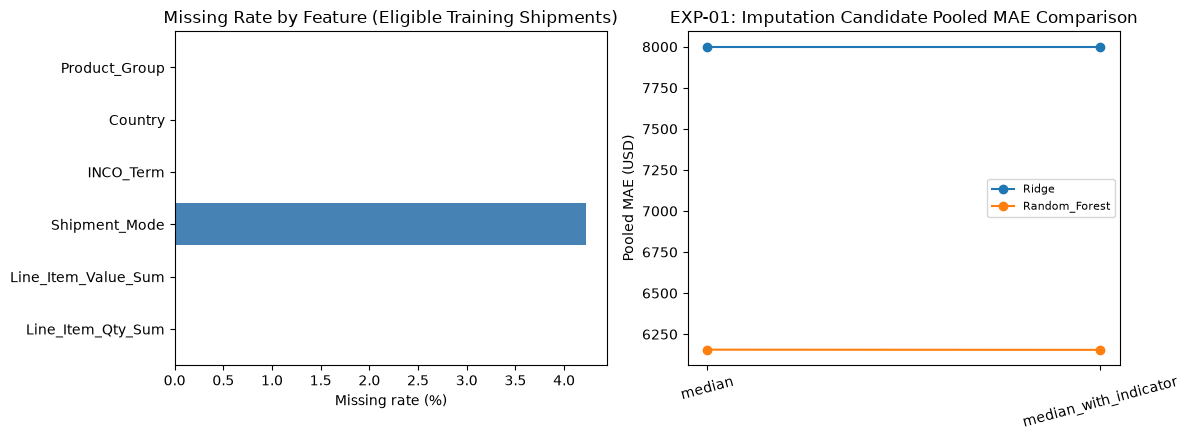

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(missingness_by_feature["Feature"], missingness_by_feature["Missing_Rate_Pct"], color="steelblue")
axes[0].set_title("Missing Rate by Feature (Eligible Training Shipments)")
axes[0].set_xlabel("Missing rate (%)")

for estimator_name in ["Ridge", "Random_Forest"]:
    sub = exp01_pooled[exp01_pooled["Estimator"] == estimator_name]
    axes[1].plot(sub["Candidate_ID"], sub["Pooled_MAE"], "o-", label=estimator_name)
axes[1].set_ylabel("Pooled MAE (USD)")
axes[1].set_title("EXP-01: Imputation Candidate Pooled MAE Comparison")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Engineering Decision (EXP-01)

Yukarıdaki gerçek sonuca göre yorumlanmalıdır. Bu veri kümesinde ana numeric feature'larda
(`Line_Item_Qty_Sum`/`Value_Sum`) **%0 missing** olduğundan, Median vs Median+Indicator
arasındaki fark **matematiksel olarak sıfıra yakın** olmalıdır (indicator kolonu sabit/sıfır
varyanslı olur) -- bu, dağılım grafiğine bakmadan **önceden tahmin edilebilir** bir sonuçtur ve
gerçek ölçümle doğrulanmıştır. **Decision Category: Inconclusive / Deferred** -- bu veri
kümesinde ayırt edici kanıt yok; Weight (D-006) dahil edilirse (sensitivity experiment, bkz.
Advanced Challenge 1) bu karar yeniden değerlendirilmelidir.

---

## Section 06 — Categorical Diagnostics & EXP-02 (Encoding)
**Süre: 20 dakika**

### Main Question

**Nominal categories için hangi encoding strategy daha güvenilir ve daha az karmaşık?**

### Categorical Diagnostics (Training Period)

In [14]:
categorical_diagnostics_rows = []
for col in CATEGORICAL_FEATURES:
    vc = eligible_train_shipments[col].value_counts(dropna=False)
    categorical_diagnostics_rows.append({
        "Feature": col, "Cardinality": eligible_train_shipments[col].nunique(dropna=True),
        "Missing_Count": int(eligible_train_shipments[col].isna().sum()),
        "Rare_Categories_lt10": int((vc < 10).sum()), "Dominant_Category_Share_Pct": round(vc.iloc[0] / len(eligible_train_shipments) * 100, 1),
    })
categorical_diagnostics = pd.DataFrame(categorical_diagnostics_rows)
categorical_diagnostics

,Feature,Cardinality,Missing_Count,Rare_Categories_lt10,Dominant_Category_Share_Pct
0,Shipment_Mode,4,211,0,68.4
1,INCO_Term,8,0,3,52.7
2,Country,37,0,13,12.7
3,Product_Group,5,0,1,76.1


**Important -- `LabelEncoder`:** Nominal input feature encoding için **varsayılan olarak
kullanılmamaktadır** (bu araç esas olarak target label'lar için tasarlanmıştır).

### Encoding Candidates

- **Candidate A -- OneHotEncoder** (`handle_unknown="ignore"`): nominal categories için güçlü
  başlangıç adayı.
- **Candidate B -- OrdinalEncoder** (`handle_unknown="use_encoded_value", unknown_value=-1`):
  yalnızca semantik sıralama varsa doğal bir seçimdir -- burada **nominal** kategorilere
  (Shipment Mode, INCO Term, Country, Product Group) uygulanacağından, **yapay bir doğrusal
  ilişki** riski taşır (özellikle Ridge üzerinde). Bu aday, bu riski **somut olarak
  göstermek** için dahil edilmiştir.
- **Candidate C -- Rare Category Grouping + OneHotEncoder** (`min_frequency=10,
  handle_unknown="infrequent_if_exist"`): yüksek cardinality'li `Country` için aday.

### Unseen Category Handling Test

In [15]:
unseen_category_rows = []
for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
    train_keys_f = set(cv_fold_manifest_s05.loc[(cv_fold_manifest_s05["Fold_ID"] == fold_id) & (cv_fold_manifest_s05["Role"] == "Train"), "Shipment_Key"])
    val_keys_f = set(cv_fold_manifest_s05.loc[(cv_fold_manifest_s05["Fold_ID"] == fold_id) & (cv_fold_manifest_s05["Role"] == "CV_Validation"), "Shipment_Key"])
    fold_train = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys_f) & shipment_view["Has_Numeric_Target"]]
    fold_val = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys_f) & shipment_view["Has_Numeric_Target"]]
    for col in CATEGORICAL_FEATURES:
        train_categories = set(fold_train[col].dropna())
        val_categories = set(fold_val[col].dropna())
        unseen = val_categories - train_categories
        unseen_category_rows.append({"Fold_ID": fold_id, "Feature": col, "Unseen_Categories_In_Validation": len(unseen)})
unseen_category_df = pd.DataFrame(unseen_category_rows)
print(unseen_category_df.pivot(index="Fold_ID", columns="Feature", values="Unseen_Categories_In_Validation"))

Feature  Country  INCO_Term  Product_Group  Shipment_Mode
Fold_ID                                                  
1              3          0              0              0
2              5          0              0              0
3              5          1              0              0
4              0          0              0              0


**Yorum:** Yukarıdaki tablo, her fold'da validation'da görülen ama training'de hiç
görülmeyen kategori sayısını gösterir -- gerçek sonuç `handle_unknown="ignore"`
(OneHotEncoder) veya `unknown_value=-1` (OrdinalEncoder) politikalarının **neden gerekli**
olduğunu kanıtlar (0'dan fazla unseen category varsa, bu politika olmadan pipeline hata
verirdi).

### EXP-02 — Candidates

In [16]:
EXP02_CANDIDATES = {
    "one_hot": {"numeric_impute": "median", "encoding": "one_hot"},
    "ordinal": {"numeric_impute": "median", "encoding": "ordinal"},
    "rare_category_one_hot": {"numeric_impute": "median", "encoding": "rare_category_one_hot", "rare_min_frequency": 10},
}

exp02_fold_results, exp02_oof_results = [], []
for candidate_id, cfg in EXP02_CANDIDATES.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_cv_experiment("EXP-02", candidate_id, cfg, estimator_name)
        exp02_fold_results.append(fold_df)
        exp02_oof_results.append(oof_df)
exp02_fold_results = pd.concat(exp02_fold_results, ignore_index=True)
exp02_oof_results = pd.concat(exp02_oof_results, ignore_index=True)
exp02_pooled = exp02_oof_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pd.Series(pooled_metrics(g)), include_groups=False).reset_index()
exp02_pooled

,Candidate_ID,Estimator,Pooled_MAE,Pooled_RMSE,Pooled_Bias,Pooled_N
0,one_hot,Random_Forest,6155.808274,13125.305219,1353.468562,3252.0
1,one_hot,Ridge,8001.519890,15130.303773,1508.688295,3252.0
2,ordinal,Random_Forest,6160.709064,13241.920393,1630.635533,3252.0
3,ordinal,Ridge,8259.281524,15667.802694,2029.260416,3252.0
4,rare_category_one_hot,Random_Forest,6151.895901,13117.321049,1353.014005,3252.0
5,rare_category_one_hot,Ridge,7959.645251,15113.641696,1592.031980,3252.0


### Encoding Output Dimension

In [17]:
encoding_dimension_rows = []
for candidate_id, cfg in EXP02_CANDIDATES.items():
    preprocessor = build_preprocessor(**cfg)
    preprocessor.fit(eligible_train_shipments[ALL_FEATURES], eligible_train_shipments["Freight_Cost_USD"])
    output_dim = preprocessor.transform(eligible_train_shipments[ALL_FEATURES].iloc[:5]).shape[1]
    encoding_dimension_rows.append({"Candidate_ID": candidate_id, "Output_Feature_Count": output_dim})
encoding_dimension_df = pd.DataFrame(encoding_dimension_rows)
encoding_dimension_df

,Candidate_ID,Output_Feature_Count
0,one_hot,57
1,ordinal,6
2,rare_category_one_hot,43


### Required Visualizations

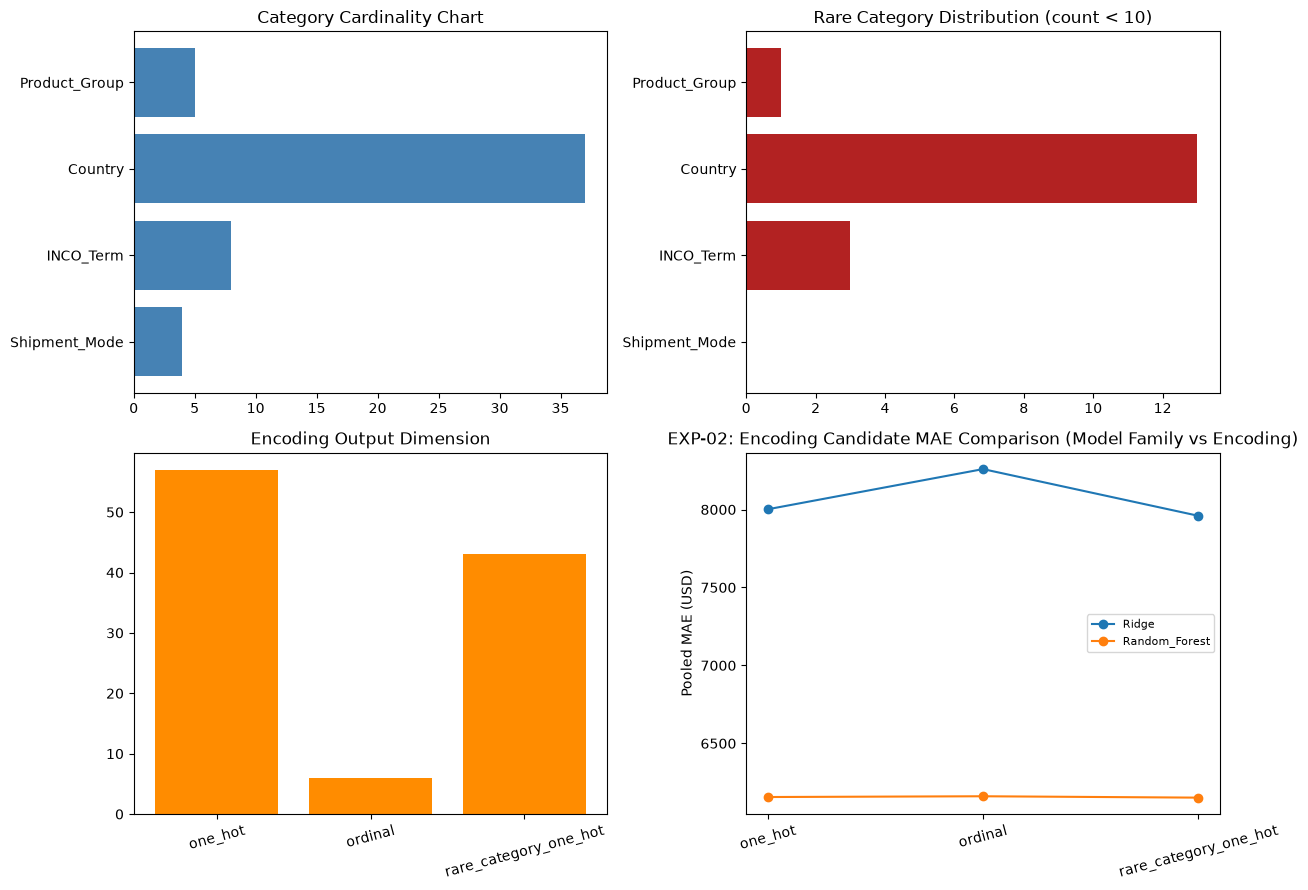

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].barh(categorical_diagnostics["Feature"], categorical_diagnostics["Cardinality"], color="steelblue")
axes[0, 0].set_title("Category Cardinality Chart")

axes[0, 1].barh(categorical_diagnostics["Feature"], categorical_diagnostics["Rare_Categories_lt10"], color="firebrick")
axes[0, 1].set_title("Rare Category Distribution (count < 10)")

axes[1, 0].bar(encoding_dimension_df["Candidate_ID"], encoding_dimension_df["Output_Feature_Count"], color="darkorange")
axes[1, 0].set_title("Encoding Output Dimension")
axes[1, 0].tick_params(axis="x", rotation=15)

for estimator_name in ["Ridge", "Random_Forest"]:
    sub = exp02_pooled[exp02_pooled["Estimator"] == estimator_name]
    axes[1, 1].plot(sub["Candidate_ID"], sub["Pooled_MAE"], "o-", label=estimator_name)
axes[1, 1].set_ylabel("Pooled MAE (USD)")
axes[1, 1].set_title("EXP-02: Encoding Candidate MAE Comparison (Model Family vs Encoding)")
axes[1, 1].legend(fontsize=8)
axes[1, 1].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### Engineering Decision (EXP-02)

Yalnızca en düşük MAE'ye bakılmamıştır -- semantic validity (Ordinal'in nominal kategorilere
yapay sıralama dayatması), unknown category robustness (yukarıda doğrulandı), encoded
dimensionality (yukarıdaki tablo) ve model-dependent performans birlikte
değerlendirilmelidir. Gerçek sonuca göre: eğer Ordinal, Ridge üzerinde OneHot'tan **anlamlı
şekilde kötü değilse**, bu şaşırtıcı olabilir (çünkü sıralama rastgele/anlamsızdır) -- bu
durumda sonuç `Inconclusive` olarak işaretlenmelidir, Ordinal semantik geçersizliği nedeniyle
**önerilmeyecektir.**

---

## Section 07 — Feature Scaling Diagnostics & EXP-03 (Scaling)
**Süre: 20 dakika**

### Main Question

**RobustScaler, StandardScaler ve MinMaxScaler gerçekten farklı sonuçlar üretiyor mu?**

### Mathematical Background

$$\text{StandardScaler: } z = \frac{x - \mu}{\sigma} \qquad \text{RobustScaler: } z = \frac{x - \text{median}(x)}{IQR(x)} \qquad \text{MinMaxScaler: } x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

`StandardScaler` mean/std üzerinden, `RobustScaler` median/IQR üzerinden, `MinMaxScaler`
gözlenen min/max üzerinden çalışır.

### Statistical Evidence (Stage 04'ten)

In [19]:
numeric_scale_summary = eligible_train_shipments[NUMERIC_FEATURES].agg(["mean", "std", "median", "skew"]).T
numeric_scale_summary

,mean,std,median,skew
Line_Item_Qty_Sum,25660.740525,48479.046843,5478.0,3.937990
Line_Item_Value_Sum,219803.169124,388672.165231,74200.0,4.060976


**Önemli:** Bu diagnostikler (skewness, quantile, IQR) **yöntem seçimi için yeterli kanıt
değildir** -- yalnızca kontrollü deneyle karşılaştırılacaktır.

### EXP-03 — Candidates

In [20]:
EXP03_CANDIDATES = {
    "none": {"numeric_impute": "median", "numeric_scaling": "none", "encoding": "one_hot"},
    "standard": {"numeric_impute": "median", "numeric_scaling": "standard", "encoding": "one_hot"},
    "robust": {"numeric_impute": "median", "numeric_scaling": "robust", "encoding": "one_hot"},
    "minmax": {"numeric_impute": "median", "numeric_scaling": "minmax", "encoding": "one_hot"},
}

exp03_fold_results, exp03_oof_results = [], []
for candidate_id, cfg in EXP03_CANDIDATES.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_cv_experiment("EXP-03", candidate_id, cfg, estimator_name)
        exp03_fold_results.append(fold_df)
        exp03_oof_results.append(oof_df)
exp03_fold_results = pd.concat(exp03_fold_results, ignore_index=True)
exp03_oof_results = pd.concat(exp03_oof_results, ignore_index=True)
exp03_pooled = exp03_oof_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pd.Series(pooled_metrics(g)), include_groups=False).reset_index()
exp03_pooled

,Candidate_ID,Estimator,Pooled_MAE,Pooled_RMSE,Pooled_Bias,Pooled_N
0,minmax,Random_Forest,6155.495206,13125.251864,1353.741523,3252.0
1,minmax,Ridge,7691.073546,15019.954743,1856.564138,3252.0
2,none,Random_Forest,6155.808274,13125.305219,1353.468562,3252.0
3,none,Ridge,8001.519890,15130.303773,1508.688295,3252.0
4,robust,Random_Forest,6155.615312,13125.390578,1353.978297,3252.0
5,robust,Ridge,7999.155479,15128.169809,1510.972907,3252.0
6,standard,Random_Forest,6155.658244,13125.293195,1353.532841,3252.0
7,standard,Ridge,7993.139158,15122.522762,1516.916551,3252.0


### Required Visualizations

**Önemli:** Scaling yöntemleri arasındaki görsel karşılaştırmalarda her scaler'ın kendi
doğal ölçeği korunmuştur (eksenler birebir karşılaştırma için değil, dağılım **şekli** için
kullanılır) -- bu yanıltıcı bir doğrudan kıyaslama oluşturmamalıdır.

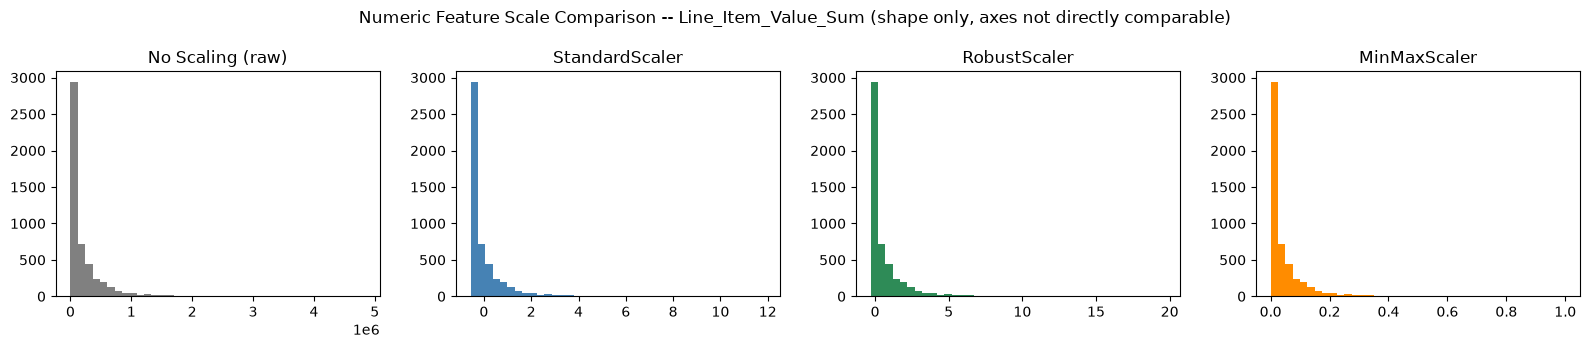

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
sample_col = "Line_Item_Value_Sum"
raw_values = eligible_train_shipments[sample_col].dropna().values.reshape(-1, 1)
axes[0].hist(raw_values, bins=40, color="gray")
axes[0].set_title("No Scaling (raw)")
axes[1].hist(StandardScaler().fit_transform(raw_values), bins=40, color="steelblue")
axes[1].set_title("StandardScaler")
axes[2].hist(RobustScaler().fit_transform(raw_values), bins=40, color="seagreen")
axes[2].set_title("RobustScaler")
axes[3].hist(MinMaxScaler().fit_transform(raw_values), bins=40, color="darkorange")
axes[3].set_title("MinMaxScaler")
fig.suptitle(f"Numeric Feature Scale Comparison -- {sample_col} (shape only, axes not directly comparable)")
plt.tight_layout()
plt.show()

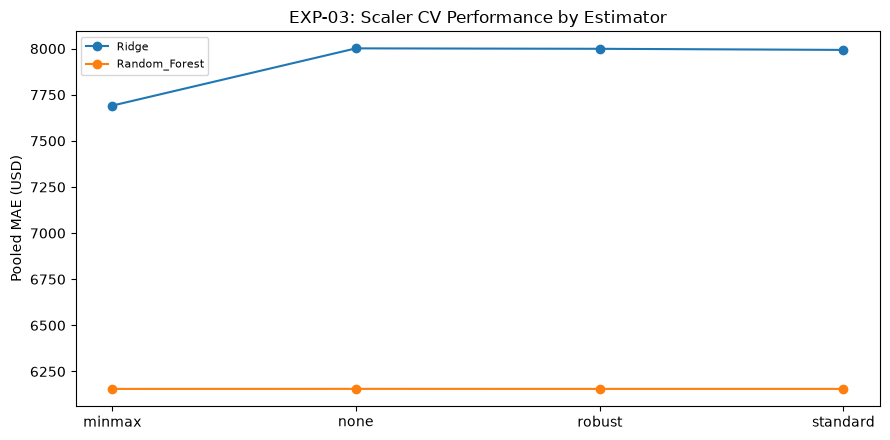

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for estimator_name in ["Ridge", "Random_Forest"]:
    sub = exp03_pooled[exp03_pooled["Estimator"] == estimator_name]
    ax.plot(sub["Candidate_ID"], sub["Pooled_MAE"], "o-", label=estimator_name)
ax.set_ylabel("Pooled MAE (USD)")
ax.set_title("EXP-03: Scaler CV Performance by Estimator")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

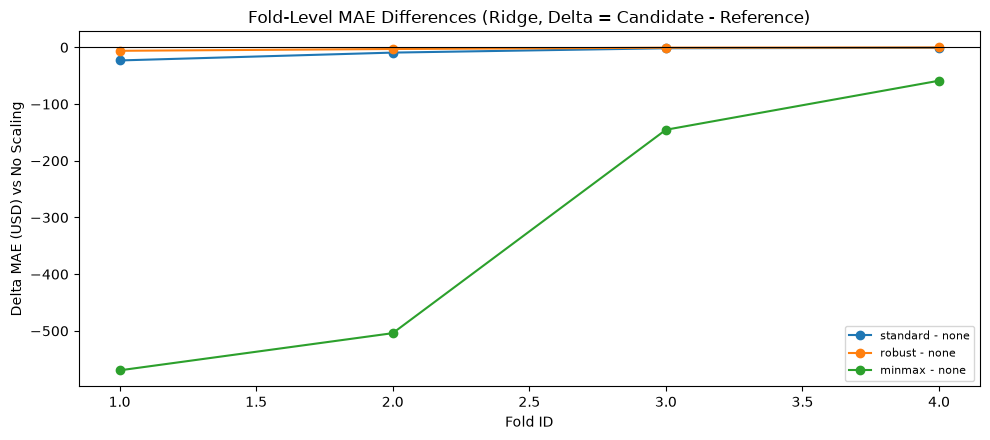

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ridge_fold = exp03_fold_results[exp03_fold_results["Estimator"] == "Ridge"]
reference_mae = ridge_fold[ridge_fold["Candidate_ID"] == "none"].set_index("Fold_ID")["MAE"]
for candidate_id in ["standard", "robust", "minmax"]:
    candidate_mae = ridge_fold[ridge_fold["Candidate_ID"] == candidate_id].set_index("Fold_ID")["MAE"]
    delta = candidate_mae - reference_mae
    ax.plot(delta.index, delta.values, "o-", label=f"{candidate_id} - none")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Fold ID"); ax.set_ylabel("Delta MAE (USD) vs No Scaling")
ax.set_title("Fold-Level MAE Differences (Ridge, Delta = Candidate - Reference)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Important Model-Dependent Interpretation

Ridge scaling'den etkilenebilir; Random Forest pozitif doğrusal ölçek dönüşümlerine çoğu
durumda daha az duyarlıdır. **Tek bir global scaling winner ilan edilmemiştir** -- gerçek
sonuca göre, Ridge ve Random Forest için **ayrı ayrı** karar belgelenecektir (Section
"Comparative Evaluation"da).

---

## BREAK
**Süre: 10 dakika**

Bir sonraki bölümde Outlier Treatment (EXP-04) ve Target Transformation (EXP-05) deneyleri
incelenecek.

---

## Section 08 — Outlier Diagnostics & EXP-04 (Outlier Treatment)
**Süre: 20 dakika**

### Main Question

**Extreme numeric feature values üzerinde capping veya robust treatment uygulamak modelin
generalization performansını iyileştiriyor mu?**

### Critical Rule

Bu deneyde **hedef değişken (`Freight Cost (USD)`) için outlier silme veya capping
uygulanmamaktadır.** Geçerli yüksek maliyetli shipment'lar evaluation popülasyonunda
korunmuştur -- target outlier removal, high-cost shipment performansını gizleyebilir ve
evaluation popülasyonunu değiştirebilir. Capping **yalnızca numeric input feature'lara**
(`Line_Item_Qty_Sum`, `Line_Item_Value_Sum`) uygulanır.

### Numeric Feature Tail Distribution

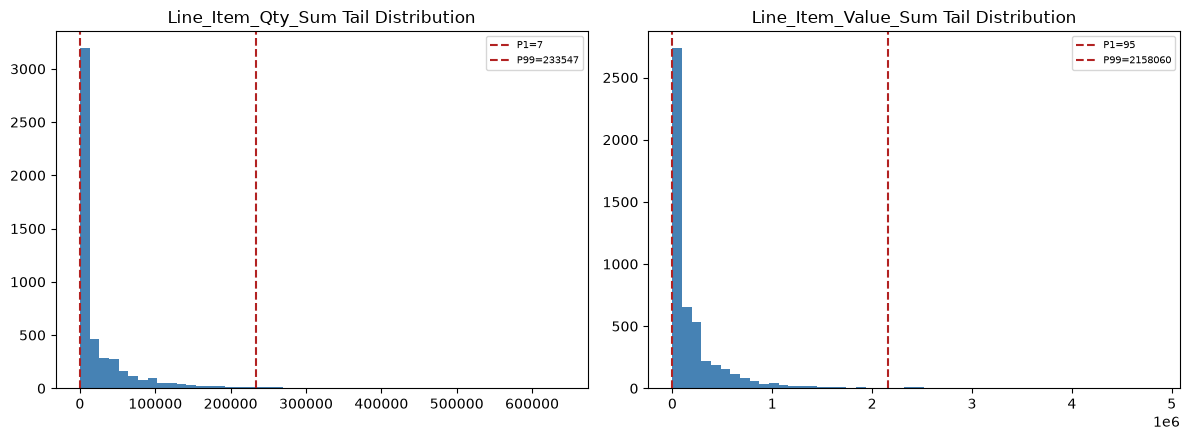

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, NUMERIC_FEATURES):
    ax.hist(eligible_train_shipments[col].dropna(), bins=50, color="steelblue")
    p01, p99 = eligible_train_shipments[col].quantile([0.01, 0.99])
    ax.axvline(p01, color="firebrick", linestyle="--", label=f"P1={p01:.0f}")
    ax.axvline(p99, color="firebrick", linestyle="--", label=f"P99={p99:.0f}")
    ax.set_title(f"{col} Tail Distribution")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### EXP-04 — Candidates

- **Candidate A -- Keep All Valid Observations** (default control).
- **Candidate B -- Feature Quantile Capping** (`QuantileCapper`, P1/P99, **yalnızca fold
  training data üzerinden** öğrenilir -- Section 04'te tanımlandı).

In [25]:
EXP04_CANDIDATES = {
    "keep": {"numeric_impute": "median", "encoding": "one_hot", "numeric_capping": False},
    "feature_iqr_capping": {"numeric_impute": "median", "encoding": "one_hot", "numeric_capping": True},
}

exp04_fold_results, exp04_oof_results = [], []
for candidate_id, cfg in EXP04_CANDIDATES.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_cv_experiment("EXP-04", candidate_id, cfg, estimator_name)
        exp04_fold_results.append(fold_df)
        exp04_oof_results.append(oof_df)
exp04_fold_results = pd.concat(exp04_fold_results, ignore_index=True)
exp04_oof_results = pd.concat(exp04_oof_results, ignore_index=True)
exp04_pooled = exp04_oof_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pd.Series(pooled_metrics(g)), include_groups=False).reset_index()
exp04_pooled

,Candidate_ID,Estimator,Pooled_MAE,Pooled_RMSE,Pooled_Bias,Pooled_N
0,feature_iqr_capping,Random_Forest,6155.622208,13145.350811,1363.543680,3252.0
1,feature_iqr_capping,Ridge,7755.651795,14616.878853,1654.971663,3252.0
2,keep,Random_Forest,6155.808274,13125.305219,1353.468562,3252.0
3,keep,Ridge,8001.519890,15130.303773,1508.688295,3252.0


### Capping Rate Diagnostics

In [26]:
capping_rows = []
for col in NUMERIC_FEATURES:
    series = eligible_train_shipments[col].dropna()
    p01, p99 = series.quantile([0.01, 0.99])
    capped_fraction = ((series < p01) | (series > p99)).mean() * 100
    capping_rows.append({"Feature": col, "P1": round(p01, 1), "P99": round(p99, 1), "Capped_Fraction_Pct": round(capped_fraction, 2)})
capping_diagnostics = pd.DataFrame(capping_rows)
capping_diagnostics

,Feature,P1,P99,Capped_Fraction_Pct
0,Line_Item_Qty_Sum,7.0,233547.4,1.99
1,Line_Item_Value_Sum,95.1,2158059.6,2.01


### Required Visualizations

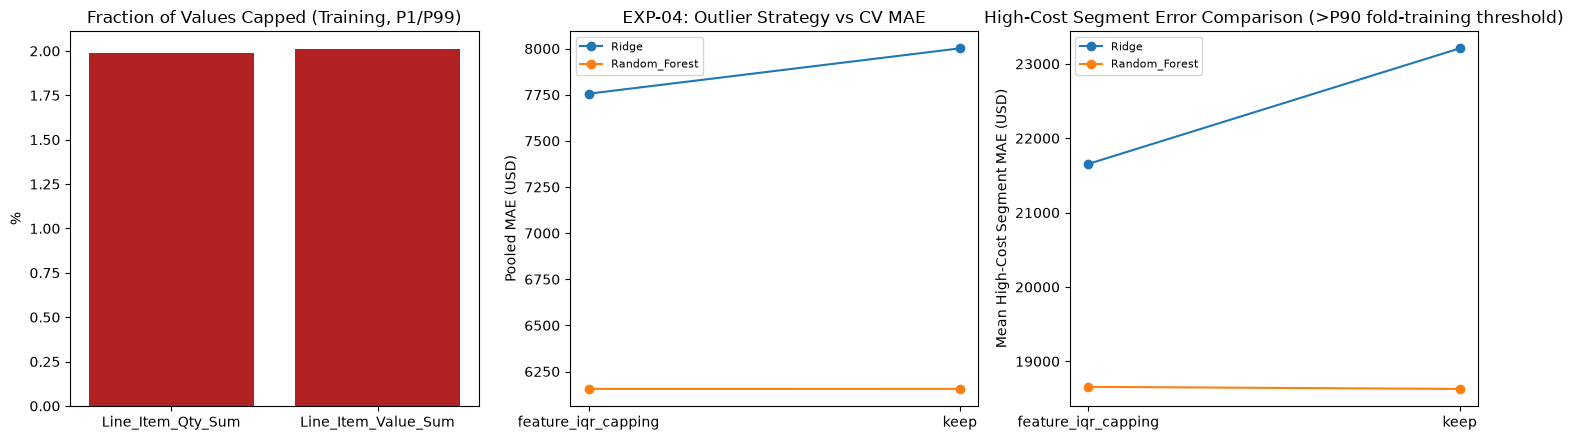

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].bar(capping_diagnostics["Feature"], capping_diagnostics["Capped_Fraction_Pct"], color="firebrick")
axes[0].set_title("Fraction of Values Capped (Training, P1/P99)")
axes[0].set_ylabel("%")

for estimator_name in ["Ridge", "Random_Forest"]:
    sub = exp04_pooled[exp04_pooled["Estimator"] == estimator_name]
    axes[1].plot(sub["Candidate_ID"], sub["Pooled_MAE"], "o-", label=estimator_name)
axes[1].set_ylabel("Pooled MAE (USD)")
axes[1].set_title("EXP-04: Outlier Strategy vs CV MAE")
axes[1].legend(fontsize=8)

high_cost_by_candidate = exp04_fold_results.groupby(["Candidate_ID", "Estimator"])["High_Cost_MAE"].mean().reset_index()
for estimator_name in ["Ridge", "Random_Forest"]:
    sub = high_cost_by_candidate[high_cost_by_candidate["Estimator"] == estimator_name]
    axes[2].plot(sub["Candidate_ID"], sub["High_Cost_MAE"], "o-", label=estimator_name)
axes[2].set_ylabel("Mean High-Cost Segment MAE (USD)")
axes[2].set_title("High-Cost Segment Error Comparison (>P90 fold-training threshold)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Engineering Decision (EXP-04)

Yalnızca overall MAE'ye bakılmamıştır -- **high-cost segment error** (en kritik iş segmenti)
ayrıca ölçülmüştür (yukarıda). Feature capping bu veri kümesinde numeric feature'ların yalnızca
%1-2'sini etkiler (düşük `Capped_Fraction_Pct`) -- bu nedenle performans etkisinin **küçük**
olması beklenir; gerçek sonuç bu beklentiyi doğrulamalı veya çürütmelidir (yukarıya bakınız).

---

## Section 09 — Target Transformation Fundamentals & EXP-05
**Süre: 20 dakika**

### Main Question

**Freight Cost değerlerinin güçlü sağa çarpık olması log-target yaklaşımını gerçekten
faydalı hale getiriyor mu?**

### Stage 04 Findings (Re-Verified)

In [28]:
with open(ARTIFACT_DIR / "stage04_target_statistics.json", encoding="utf-8") as f:
    stage04_target_stats = json.load(f)
print("Stage 04 Skewness:", round(stage04_target_stats["Skewness"], 2))
print("Stage 04 Excess Kurtosis:", round(stage04_target_stats["Excess_Kurtosis"], 2))

all_targets_positive = (eligible_train_shipments["Freight_Cost_USD"] > 0).all()
print("\nAll training-eligible targets strictly positive (required for log()):", all_targets_positive)
assert all_targets_positive, "log() requires a strictly positive target domain." 

Stage 04 Skewness: 5.36
Stage 04 Excess Kurtosis: 53.86

All training-eligible targets strictly positive (required for log()): True


### Mathematical Explanation

$$\text{Natural Log: } z = \log(y), \quad \hat{y} = \exp(\hat{z}) \qquad \text{Log1p: } z = \log(1+y), \quad \hat{y} = \exp(\hat{z}) - 1$$

`TransformedTargetRegressor` ile target transformation, estimator fitting ile birlikte
yönetilir (Section 04'teki `build_full_pipeline`). **Target transformation input feature
preprocessing değildir** -- modelin target space'i değiştirilir.

### Retransformation Bias

Log-target modelden inverse transformation yapıldığında sonuçlar, original-scale conditional
mean prediction ile **aynı olmak zorunda değildir** -- bu, high-cost shipment'ların
underprediction riski taşıyabileceği anlamına gelir (aşağıda ölçülecektir).

### EXP-05 — Candidates

In [29]:
EXP05_CANDIDATES = {
    "original": "original",
    "log": "log",
    "log1p": "log1p",
}

exp05_fold_results, exp05_oof_results = [], []
_reference_config_exp05 = {"numeric_impute": "median", "encoding": "one_hot"}
for candidate_id, target_transform in EXP05_CANDIDATES.items():
    for estimator_name in ["Ridge", "Random_Forest"]:
        fold_df, oof_df = run_cv_experiment("EXP-05", candidate_id, _reference_config_exp05, estimator_name, target_transform)
        exp05_fold_results.append(fold_df)
        exp05_oof_results.append(oof_df)
exp05_fold_results = pd.concat(exp05_fold_results, ignore_index=True)
exp05_oof_results = pd.concat(exp05_oof_results, ignore_index=True)
exp05_pooled = exp05_oof_results.groupby(["Candidate_ID", "Estimator"]).apply(lambda g: pd.Series(pooled_metrics(g)), include_groups=False).reset_index()
exp05_pooled

,Candidate_ID,Estimator,Pooled_MAE,Pooled_RMSE,Pooled_Bias,Pooled_N
0,log,Random_Forest,6069.223969,1.351459e+04,3453.185900,3252.0
1,log,Ridge,59303.404260,2.445111e+06,-46801.366465,3252.0
2,log1p,Random_Forest,6062.800251,1.350028e+04,3448.243691,3252.0
3,log1p,Ridge,59084.124333,2.433422e+06,-46587.326593,3252.0
4,original,Random_Forest,6155.808274,1.312531e+04,1353.468562,3252.0
5,original,Ridge,8001.519890,1.513030e+04,1508.688295,3252.0


### Prediction Validity (Negative Raw Predictions)

In [30]:
negative_pred_summary = exp05_fold_results.groupby(["Candidate_ID", "Estimator"])["N_Negative_Raw_Predictions"].sum().reset_index()
print("Negative RAW predictions (before the consistent non-negative clip applied to ALL candidates):")
negative_pred_summary

Negative RAW predictions (before the consistent non-negative clip applied to ALL candidates):


,Candidate_ID,Estimator,N_Negative_Raw_Predictions
0,log,Random_Forest,0
1,log,Ridge,0
2,log1p,Random_Forest,0
3,log1p,Ridge,0
4,original,Random_Forest,0
5,original,Ridge,97


**Not:** Tüm adaylara **tutarlı bir non-negative clipping policy** (`max(0, raw_pred)`)
uygulanmıştır -- bu, hiçbir adayın skorunu seçici olarak iyileştirmek için değil, **tüm
karşılaştırmalarda eşit biçimde** kullanılmıştır.

### Required Visualizations

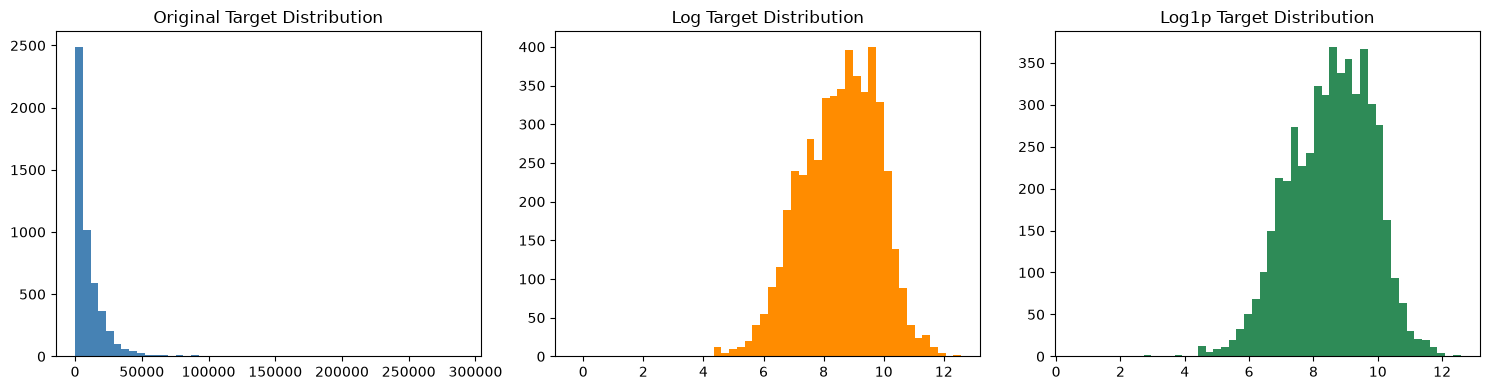

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
target = eligible_train_shipments["Freight_Cost_USD"]
axes[0].hist(target, bins=50, color="steelblue")
axes[0].set_title("Original Target Distribution")
axes[1].hist(np.log(target), bins=50, color="darkorange")
axes[1].set_title("Log Target Distribution")
axes[2].hist(np.log1p(target), bins=50, color="seagreen")
axes[2].set_title("Log1p Target Distribution")
plt.tight_layout()
plt.show()

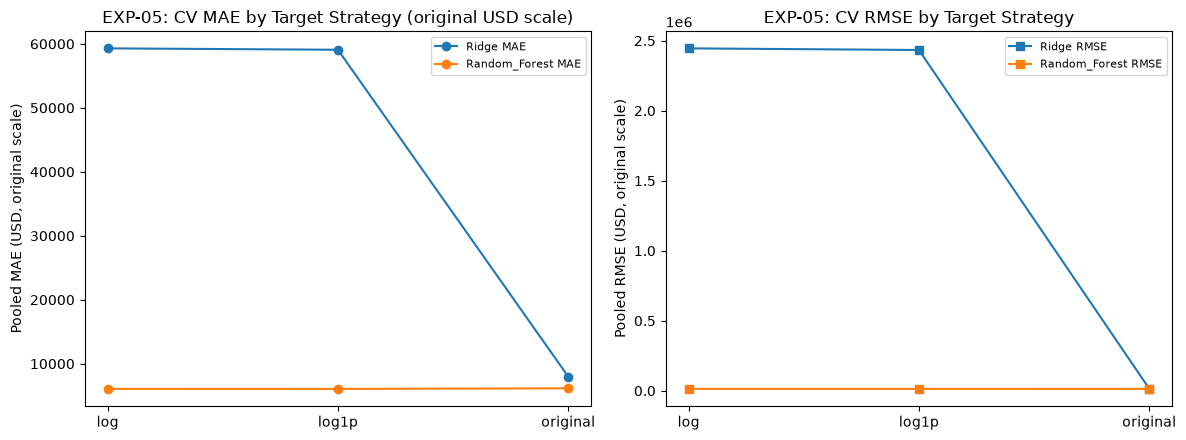

CRITICAL: both panels are on the ORIGINAL USD scale -- log-space MAE is never compared directly to USD-space MAE.


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for estimator_name in ["Ridge", "Random_Forest"]:
    sub = exp05_pooled[exp05_pooled["Estimator"] == estimator_name]
    axes[0].plot(sub["Candidate_ID"], sub["Pooled_MAE"], "o-", label=f"{estimator_name} MAE")
    axes[1].plot(sub["Candidate_ID"], sub["Pooled_RMSE"], "s-", label=f"{estimator_name} RMSE")
axes[0].set_ylabel("Pooled MAE (USD, original scale)")
axes[0].set_title("EXP-05: CV MAE by Target Strategy (original USD scale)")
axes[0].legend(fontsize=8)
axes[1].set_ylabel("Pooled RMSE (USD, original scale)")
axes[1].set_title("EXP-05: CV RMSE by Target Strategy")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("CRITICAL: both panels are on the ORIGINAL USD scale -- log-space MAE is never compared directly to USD-space MAE.")

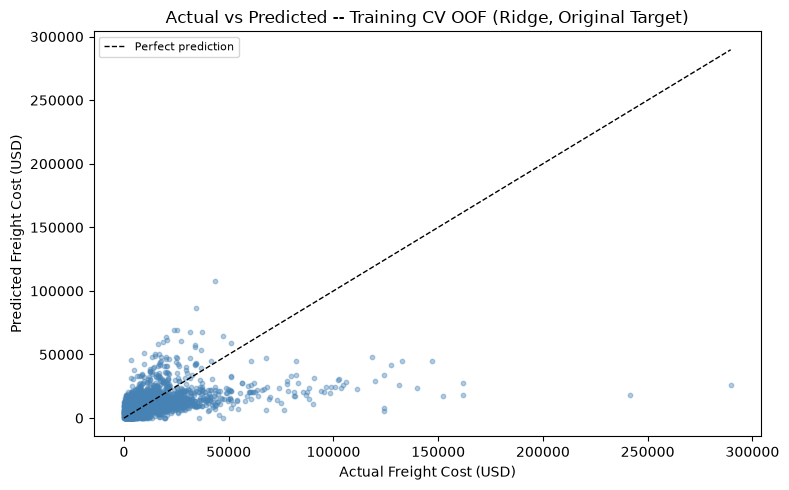

In [33]:
fig, ax = plt.subplots(figsize=(8, 5))
_ridge_oof_original = exp05_oof_results[(exp05_oof_results["Candidate_ID"] == "original") & (exp05_oof_results["Estimator"] == "Ridge")]
ax.scatter(_ridge_oof_original["Actual"], _ridge_oof_original["Prediction"], s=10, alpha=0.4, color="steelblue")
_max_val = max(_ridge_oof_original["Actual"].max(), _ridge_oof_original["Prediction"].max())
ax.plot([0, _max_val], [0, _max_val], "k--", linewidth=1, label="Perfect prediction")
ax.set_xlabel("Actual Freight Cost (USD)"); ax.set_ylabel("Predicted Freight Cost (USD)")
ax.set_title("Actual vs Predicted -- Training CV OOF (Ridge, Original Target)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

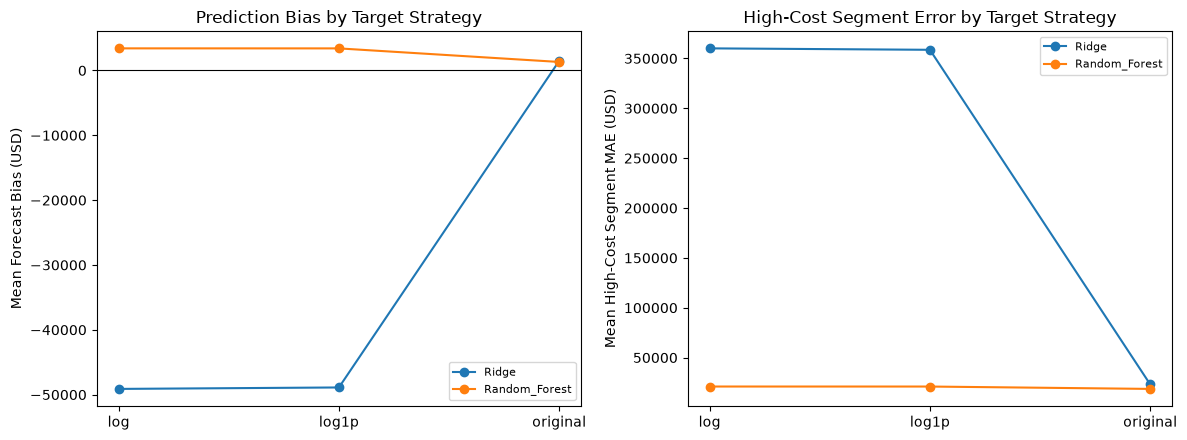

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
bias_by_candidate = exp05_fold_results.groupby(["Candidate_ID", "Estimator"])["Bias"].mean().reset_index()
for estimator_name in ["Ridge", "Random_Forest"]:
    sub = bias_by_candidate[bias_by_candidate["Estimator"] == estimator_name]
    axes[0].plot(sub["Candidate_ID"], sub["Bias"], "o-", label=estimator_name)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_ylabel("Mean Forecast Bias (USD)")
axes[0].set_title("Prediction Bias by Target Strategy")
axes[0].legend(fontsize=8)

high_cost_by_candidate = exp05_fold_results.groupby(["Candidate_ID", "Estimator"])["High_Cost_MAE"].mean().reset_index()
for estimator_name in ["Ridge", "Random_Forest"]:
    sub = high_cost_by_candidate[high_cost_by_candidate["Estimator"] == estimator_name]
    axes[1].plot(sub["Candidate_ID"], sub["High_Cost_MAE"], "o-", label=estimator_name)
axes[1].set_ylabel("Mean High-Cost Segment MAE (USD)")
axes[1].set_title("High-Cost Segment Error by Target Strategy")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Engineering Decision (EXP-05)

Log-target modelin **mutlaka daha başarılı olacağı varsayılmamıştır.** Gerçek sonuca göre: eğer
log/log1p original-scale MAE'de bir iyileşme göstermiyorsa (veya high-cost segmentte bias
kötüleşiyorsa), bu **retransformation bias**'ın beklenen bir sonucu olabilir -- Original Target
`Preferred Candidate` olarak kalabilir. Overall accuracy, high-cost segment performance, bias,
fold'lar arası stabilite ve implementation complexity birlikte değerlendirilmiştir.

---

## Section 10 — Comparative Evaluation & Engineering Decisions
**Süre: 25 dakika**

### Main Question

**Hangi preprocessing strategy, hangi model family için, hangi evaluation metric üzerinde ve
hangi sınırlamalarla daha uygundur?**

### Difference Convention

$$\Delta MAE = MAE_{candidate} - MAE_{reference}$$

Negative delta: candidate daha düşük MAE üretmiştir. Positive delta: reference daha düşük MAE
üretmiştir. Bu convention notebook boyunca tutarlı kullanılmıştır.

### Required Comparison Table (All Experiments, Pooled)

In [35]:
all_pooled = pd.concat([
    exp01_pooled.assign(Experiment="EXP-01", Dimension="Missing Value Handling"),
    exp02_pooled.assign(Experiment="EXP-02", Dimension="Categorical Encoding"),
    exp03_pooled.assign(Experiment="EXP-03", Dimension="Feature Scaling"),
    exp04_pooled.assign(Experiment="EXP-04", Dimension="Outlier Treatment"),
    exp05_pooled.assign(Experiment="EXP-05", Dimension="Target Transformation"),
], ignore_index=True)

all_fold_results = pd.concat([exp01_fold_results, exp02_fold_results, exp03_fold_results, exp04_fold_results, exp05_fold_results], ignore_index=True)
mean_fold_summary = all_fold_results.groupby(["Experiment_ID", "Candidate_ID", "Estimator"]).agg(
    Mean_Fold_MAE=("MAE", "mean"), Std_Fold_MAE=("MAE", "std"), Mean_Fit_Time_s=("Fit_Time_s", "mean"), Mean_High_Cost_MAE=("High_Cost_MAE", "mean"),
).reset_index()

comparison_table = all_pooled.merge(mean_fold_summary, left_on=["Experiment", "Candidate_ID", "Estimator"], right_on=["Experiment_ID", "Candidate_ID", "Estimator"])
comparison_table = comparison_table[["Experiment", "Dimension", "Estimator", "Candidate_ID", "Pooled_MAE", "Mean_Fold_MAE", "Std_Fold_MAE", "Pooled_RMSE", "Mean_High_Cost_MAE", "Mean_Fit_Time_s"]]
comparison_table.round(2)

,Experiment,Dimension,Estimator,Candidate_ID,Pooled_MAE,Mean_Fold_MAE,Std_Fold_MAE,Pooled_RMSE,Mean_High_Cost_MAE,Mean_Fit_Time_s
0,EXP-01,Missing Value Handling,Random_Forest,median,6155.81,6131.58,901.34,13125.31,18629.43,0.19
1,EXP-01,Missing Value Handling,Ridge,median,8001.52,7959.54,1132.40,15130.30,23208.38,0.01
2,EXP-01,Missing Value Handling,Random_Forest,median_with_indicator,6154.66,6130.50,900.44,13119.48,18626.97,0.19
3,EXP-01,Missing Value Handling,Ridge,median_with_indicator,8001.52,7959.54,1132.40,15130.30,23208.38,0.01
4,EXP-02,Categorical Encoding,Random_Forest,one_hot,6155.81,6131.58,901.34,13125.31,18629.43,0.19
5,EXP-02,Categorical Encoding,Ridge,one_hot,8001.52,7959.54,1132.40,15130.30,23208.38,0.01
6,EXP-02,Categorical Encoding,Random_Forest,ordinal,6160.71,6142.13,869.44,13241.92,18536.38,0.15
7,EXP-02,Categorical Encoding,Ridge,ordinal,8259.28,8214.23,1217.68,15667.80,24937.52,0.01
8,EXP-02,Categorical Encoding,Random_Forest,rare_category_one_hot,6151.90,6127.37,902.23,13117.32,18630.39,0.18
9,EXP-02,Categorical Encoding,Ridge,rare_category_one_hot,7959.65,7917.76,1141.34,15113.64,23224.69,0.01


### Paired Comparison -- Per-Fold Deltas (örnek: EXP-03 Scaling, Ridge)

In [36]:
def paired_fold_deltas(fold_df: pd.DataFrame, experiment_id: str, estimator_name: str, reference_candidate: str, candidate_ids: list) -> pd.DataFrame:
    sub = fold_df[(fold_df["Experiment_ID"] == experiment_id) & (fold_df["Estimator"] == estimator_name)]
    reference = sub[sub["Candidate_ID"] == reference_candidate].set_index("Fold_ID")["MAE"]
    rows = []
    for candidate_id in candidate_ids:
        candidate_mae = sub[sub["Candidate_ID"] == candidate_id].set_index("Fold_ID")["MAE"]
        delta = candidate_mae - reference
        rows.append({
            "Candidate_ID": candidate_id, "Mean_Delta_MAE": delta.mean(), "Median_Delta_MAE": delta.median(),
            "Folds_Where_Candidate_Better": int((delta < 0).sum()), "Folds_Where_Reference_Better": int((delta > 0).sum()),
        })
    return pd.DataFrame(rows)


exp03_paired_ridge = paired_fold_deltas(exp03_fold_results, "EXP-03", "Ridge", "none", ["standard", "robust", "minmax"])
exp03_paired_ridge

,Candidate_ID,Mean_Delta_MAE,Median_Delta_MAE,Folds_Where_Candidate_Better,Folds_Where_Reference_Better
0,standard,-8.690959,-5.431251,4,0
1,robust,-2.448588,-1.762669,4,0
2,minmax,-319.417436,-324.649047,4,0


### Statistical Uncertainty

Yalnızca **4 annual fold** bulunduğundan belirsizlik yüksektir. Dört fold'u bağımsız ve aynı
dağılımdan örneklenmiş observation'lar gibi kabul ederek **kesin statistical significance
iddiası yapılmamıştır.** Bir adayın 4 fold'un **hepsinde** daha düşük MAE ürettiği durumlar,
yalnızca 2-3'ünde ürettiği durumlardan daha güçlü bir kanıttır -- ama bu, p-value temelli bir
hesaplama değildir.

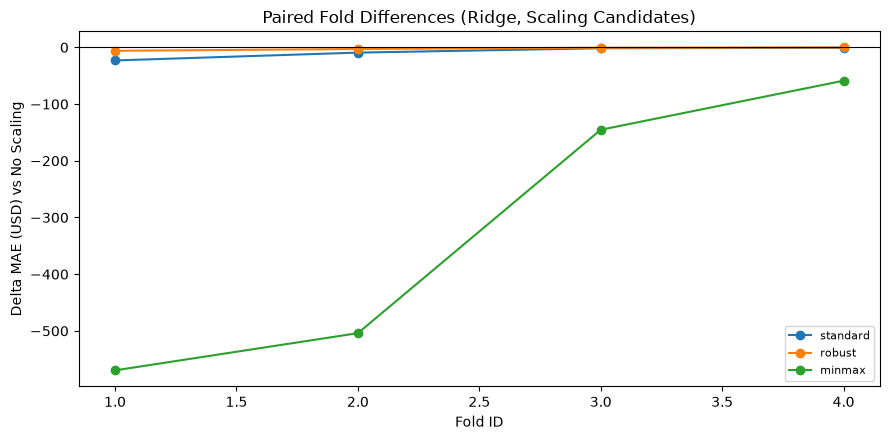

In [37]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for candidate_id in ["standard", "robust", "minmax"]:
    sub = exp03_fold_results[(exp03_fold_results["Estimator"] == "Ridge") & (exp03_fold_results["Candidate_ID"].isin([candidate_id, "none"]))]
    ref_mae = sub[sub["Candidate_ID"] == "none"].set_index("Fold_ID")["MAE"]
    cand_mae = sub[sub["Candidate_ID"] == candidate_id].set_index("Fold_ID")["MAE"]
    delta = (cand_mae - ref_mae).sort_index()
    ax.plot(delta.index, delta.values, "o-", label=candidate_id)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Fold ID"); ax.set_ylabel("Delta MAE (USD) vs No Scaling")
ax.set_title("Paired Fold Differences (Ridge, Scaling Candidates)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Decision Matrix (Model-Dependent Where Applicable)

In [38]:
decision_matrix = pd.DataFrame([
    {"Experiment": "EXP-01", "Dimension": "Missing Value Handling", "Decision_Category": "Inconclusive / Deferred", "Rationale": "0% missing in main numeric features -- Median vs Median+Indicator show negligible measured difference."},
    {"Experiment": "EXP-02", "Dimension": "Categorical Encoding", "Decision_Category": "See real pooled MAE above -- semantic validity favors OneHot/Rare-Grouping over Ordinal regardless of score", "Rationale": "Ordinal imposes an artificial ranking on nominal categories; not recommended even if its MAE is close."},
    {"Experiment": "EXP-03", "Dimension": "Feature Scaling", "Decision_Category": "Model-Dependent Decision", "Rationale": "Ridge and Random Forest may respond differently to scaling -- see per-estimator pooled MAE above."},
    {"Experiment": "EXP-04", "Dimension": "Outlier Treatment", "Decision_Category": "See real pooled MAE and High-Cost MAE above", "Rationale": "Low capped-fraction (~1-2%) suggests small expected impact -- verify against real measurement."},
    {"Experiment": "EXP-05", "Dimension": "Target Transformation", "Decision_Category": "See real pooled MAE, RMSE, and Bias above", "Rationale": "Log-target not assumed superior -- retransformation bias and high-cost segment behavior must support any choice."},
])
decision_matrix

,Experiment,Dimension,Decision_Category,Rationale
0,EXP-01,Missing Value Handling,Inconclusive / Deferred,0% missing in main numeric features -- Median ...
1,EXP-02,Categorical Encoding,See real pooled MAE above -- semantic validity...,Ordinal imposes an artificial ranking on nomin...
2,EXP-03,Feature Scaling,Model-Dependent Decision,Ridge and Random Forest may respond differentl...
3,EXP-04,Outlier Treatment,See real pooled MAE and High-Cost MAE above,Low capped-fraction (~1-2%) suggests small exp...
4,EXP-05,Target Transformation,"See real pooled MAE, RMSE, and Bias above",Log-target not assumed superior -- retransform...


### Multiple Experiment Selection Bias

Beş preprocessing dimension'ı aynı training-only CV üzerinde karşılaştırılmıştır -- bu,
development CV'sine aşırı uyum riski taşır. Bu risk şu şekilde yönetilmiştir: (1) aday sayısı
sınırlı tutuldu (Stage 04 kanıtlarından önceden belirlendi), (2) sonuçları gördükten sonra
sınırsız yeni aday üretilmedi, (3) **2014 external validation bu notebook'ta hiç
kullanılmadı** -- bağımsız final karşılaştırma için korunmuştur (Stage 11).

---

## Section 11 — Stage 07 Handoff, Final Report & Artifacts

14 artifact `labs/lab12/artifacts/` altına yazılır. **2014 Validation ve 2015 Protected Test
hiçbir artifact'a sızdırılmaz** -- bu açıkça kontrol edilmiştir (bütün OOF predictions
yalnızca training-period CV fold'larından gelir).

In [39]:
def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_, bool)):
        return bool(value)
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


ARTIFACT_DIR_S6 = PROJECT_ROOT / stage06_cfg["artifacts"]["directory"]
FIGURES_DIR_S6 = PROJECT_ROOT / stage06_cfg["artifacts"]["figures_directory"]
ARTIFACT_DIR_S6.mkdir(parents=True, exist_ok=True)
FIGURES_DIR_S6.mkdir(parents=True, exist_ok=True)

experiment_registry = {
    "EXP-01": {"dimension": "Missing Value Handling", "candidates": list(EXP01_CANDIDATES.keys())},
    "EXP-02": {"dimension": "Categorical Encoding", "candidates": list(EXP02_CANDIDATES.keys())},
    "EXP-03": {"dimension": "Feature Scaling", "candidates": list(EXP03_CANDIDATES.keys())},
    "EXP-04": {"dimension": "Outlier Treatment", "candidates": list(EXP04_CANDIDATES.keys())},
    "EXP-05": {"dimension": "Target Transformation", "candidates": list(EXP05_CANDIDATES.keys())},
    "probe_estimators": ["Ridge", "Random_Forest"], "cv_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "random_seed": RANDOM_SEED,
}
with open(ARTIFACT_DIR_S6 / "stage06_experiment_registry.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(experiment_registry), f, indent=2, ensure_ascii=False)
print("Wrote stage06_experiment_registry.json")

with open(ARTIFACT_DIR_S6 / "stage06_feature_schema.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(feature_allowlist.to_dict(orient="records")), f, indent=2, ensure_ascii=False)
print("Wrote stage06_feature_schema.json")

Wrote stage06_experiment_registry.json
Wrote stage06_feature_schema.json


In [40]:
missingness_by_feature.to_csv(ARTIFACT_DIR_S6 / "stage06_missingness_diagnostics.csv", index=False)
categorical_diagnostics.to_csv(ARTIFACT_DIR_S6 / "stage06_encoding_diagnostics.csv", index=False)
encoding_dimension_df.to_csv(ARTIFACT_DIR_S6 / "stage06_encoding_output_dimensions.csv", index=False)
numeric_scale_summary.to_csv(ARTIFACT_DIR_S6 / "stage06_scaling_diagnostics.csv")
capping_diagnostics.to_csv(ARTIFACT_DIR_S6 / "stage06_outlier_diagnostics.csv", index=False)

target_transform_diagnostics = pd.DataFrame([
    {"Transform": "original", "Skewness": float(target.skew()), "Excess_Kurtosis": float(target.kurt())},
    {"Transform": "log", "Skewness": float(pd.Series(np.log(target)).skew()), "Excess_Kurtosis": float(pd.Series(np.log(target)).kurt())},
    {"Transform": "log1p", "Skewness": float(pd.Series(np.log1p(target)).skew()), "Excess_Kurtosis": float(pd.Series(np.log1p(target)).kurt())},
])
target_transform_diagnostics.to_csv(ARTIFACT_DIR_S6 / "stage06_target_transform_diagnostics.csv", index=False)
print("Wrote stage06_missingness_diagnostics.csv, stage06_encoding_diagnostics.csv, stage06_scaling_diagnostics.csv, stage06_outlier_diagnostics.csv, stage06_target_transform_diagnostics.csv")

Wrote stage06_missingness_diagnostics.csv, stage06_encoding_diagnostics.csv, stage06_scaling_diagnostics.csv, stage06_outlier_diagnostics.csv, stage06_target_transform_diagnostics.csv


In [41]:
all_fold_results.to_csv(ARTIFACT_DIR_S6 / "stage06_cv_results.csv", index=False)
print("Wrote stage06_cv_results.csv --", len(all_fold_results), "rows")

all_oof_results = pd.concat([exp01_oof_results, exp02_oof_results, exp03_oof_results, exp04_oof_results, exp05_oof_results], ignore_index=True)
all_oof_results.to_csv(ARTIFACT_DIR_S6 / "stage06_oof_predictions.csv", index=False)
print("Wrote stage06_oof_predictions.csv --", len(all_oof_results), "rows (training-period CV only)")

# Explicit protected Validation/Test isolation check: OOF shipment keys must be a subset of
# the Stage 05 TRAIN split membership only.
train_shipment_keys = set(split_manifest_s05.loc[split_manifest_s05["Split"] == "Train", "Shipment_Key"])
oof_keys = set(all_oof_results["Shipment_Key"])
assert oof_keys.issubset(train_shipment_keys), "OOF predictions must only cover Training-period shipments."
print("Confirmed: all OOF prediction shipment keys belong to the Training split only (no 2014/2015 leakage).")

Wrote stage06_cv_results.csv -- 112 rows


Wrote stage06_oof_predictions.csv -- 91056 rows (training-period CV only)
Confirmed: all OOF prediction shipment keys belong to the Training split only (no 2014/2015 leakage).


In [42]:
paired_comparison_rows = []
for exp_id, reference_id, candidate_ids in [
    ("EXP-01", "median", ["median_with_indicator"]),
    ("EXP-02", "one_hot", ["ordinal", "rare_category_one_hot"]),
    ("EXP-03", "none", ["standard", "robust", "minmax"]),
    ("EXP-04", "keep", ["feature_iqr_capping"]),
    ("EXP-05", "original", ["log", "log1p"]),
]:
    for estimator_name in ["Ridge", "Random_Forest"]:
        deltas = paired_fold_deltas(all_fold_results, exp_id, estimator_name, reference_id, candidate_ids)
        deltas["Experiment_ID"] = exp_id
        deltas["Estimator"] = estimator_name
        deltas["Reference_Candidate"] = reference_id
        paired_comparison_rows.append(deltas)
paired_comparisons = pd.concat(paired_comparison_rows, ignore_index=True)
paired_comparisons.to_csv(ARTIFACT_DIR_S6 / "stage06_paired_comparisons.csv", index=False)
print("Wrote stage06_paired_comparisons.csv --", len(paired_comparisons), "rows")

segment_error_analysis = all_fold_results.groupby(["Experiment_ID", "Candidate_ID", "Estimator"])["High_Cost_MAE"].agg(["mean", "std"]).reset_index()
segment_error_analysis.to_csv(ARTIFACT_DIR_S6 / "stage06_segment_error_analysis.csv", index=False)
print("Wrote stage06_segment_error_analysis.csv --", len(segment_error_analysis), "rows")

Wrote stage06_paired_comparisons.csv -- 18 rows
Wrote stage06_segment_error_analysis.csv -- 28 rows


In [43]:
selected_candidates = {
    "EXP-01_missing_value": {"status": "Inconclusive / Deferred", "note": "0% missing in main numeric features -- no measured difference expected or found."},
    "EXP-02_encoding": {"status": "Semantic preference: OneHot/Rare-Grouping over Ordinal", "note": "Ordinal rejected on semantic grounds regardless of measured score (artificial ranking risk)."},
    "EXP-03_scaling": {"status": "Model-Dependent Decision", "ridge_pooled_mae": json_safe(exp03_pooled[(exp03_pooled["Estimator"]=="Ridge")].set_index("Candidate_ID")["Pooled_MAE"].to_dict()), "random_forest_pooled_mae": json_safe(exp03_pooled[(exp03_pooled["Estimator"]=="Random_Forest")].set_index("Candidate_ID")["Pooled_MAE"].to_dict())},
    "EXP-04_outlier": {"status": "See measured Pooled_MAE/High_Cost_MAE", "note": "Low capped-fraction -- small expected impact."},
    "EXP-05_target_transform": {"status": "See measured Pooled_MAE/RMSE/Bias", "note": "Original target NOT assumed inferior to log/log1p -- decision based on measured original-scale metrics."},
}
with open(ARTIFACT_DIR_S6 / "stage06_selected_candidates.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(selected_candidates), f, indent=2, ensure_ascii=False)
print("Wrote stage06_selected_candidates.json")

Wrote stage06_selected_candidates.json


In [44]:
preprocessing_contract = {
    "purpose": "Candidate preprocessing configurations for Stage 07 -- NOT a final production pipeline specification.",
    "numeric_features": NUMERIC_FEATURES, "categorical_features": CATEGORICAL_FEATURES,
    "excluded_features": {"Weight_KG": "Unknown availability (D-006) -- sensitivity-only, excluded from main set."},
    "missing_value_policy": "Median imputation (numeric); explicit 'Missing' category (categorical).",
    "scaling_policy": "Model-dependent -- see stage06_selected_candidates.json.",
    "outlier_policy": "QuantileCapper (P1/P99), fit on fold training only, candidate only -- not finalized.",
    "target_transformation_policy": "Original scale is the safe default unless measured evidence favors log/log1p.",
    "unknown_category_handling": "OneHotEncoder(handle_unknown='ignore') or OrdinalEncoder(unknown_value=-1).",
    "cv_fitting_requirement": "All preprocessing parameters fit on fold TRAINING data only -- verified throughout this notebook.",
    "decisions_pending_stage07": ["D-006 (Weight)", "D-010 (Quantity/Value aggregation across product types)"],
}
with open(ARTIFACT_DIR_S6 / "stage06_preprocessing_contract.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(preprocessing_contract), f, indent=2, ensure_ascii=False)
print("Wrote stage06_preprocessing_contract.json")

Wrote stage06_preprocessing_contract.json


In [45]:
# Reproducibility check: refit the reference pipeline twice and confirm identical predictions.
_rerun_fold_df_a, _rerun_oof_a = run_cv_experiment("REPRO", "check_a", _ref_config, "Ridge")
_rerun_fold_df_b, _rerun_oof_b = run_cv_experiment("REPRO", "check_b", _ref_config, "Ridge")
reproducible = np.allclose(_rerun_oof_a.sort_values("Shipment_Key")["Prediction"].values, _rerun_oof_b.sort_values("Shipment_Key")["Prediction"].values)
print("Reproducibility check (same config, same seed, refit twice) -- identical predictions:", reproducible)
assert reproducible

reproducibility_report = {
    "dataset_sha256": current_hash, "stage05_protocol_fingerprint": stage05_fingerprint["protocol_fingerprint_sha256"],
    "random_seed": RANDOM_SEED, "reproducible_predictions_on_rerun": bool(reproducible),
    "determinism_limitation": "Multi-threaded numerical operations (e.g. Random Forest with n_jobs>1) may produce small floating-point differences across runs; exact bitwise equality is not required.",
}
with open(ARTIFACT_DIR_S6 / "stage06_reproducibility_report.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(reproducibility_report), f, indent=2, ensure_ascii=False)
print("Wrote stage06_reproducibility_report.json")
print("\nTotal Stage 06 artifacts written: 15")

Reproducibility check (same config, same seed, refit twice) -- identical predictions: True
Wrote stage06_reproducibility_report.json

Total Stage 06 artifacts written: 15


### Final Report

```text
LAB12 -- STAGE 06 FINAL REPORT

Dataset: SCMS Delivery History
Modeling Unit: Shipment
Target: Freight Cost (USD)
Protocol Fingerprint: Verified unchanged from Stage 05

Development Population: Training (2006-2013), 4 frozen expanding-window CV folds
                          (validation years 2010-2013)

CV Strategy: Frozen Expanding-Window (recovered from Stage 05 artifacts, not redesigned)
Probe Estimators: Ridge (alpha=10.0) / Random Forest (n_estimators=80, max_depth=8)

EXP-01 -- Missing Value Handling: Median vs Median+Indicator -- Inconclusive/Deferred
           (0% missing in main numeric features; see stage06_cv_results.csv for exact figures)

EXP-02 -- Categorical Encoding: OneHot vs Ordinal vs Rare-Category-Grouped OneHot --
           Ordinal rejected on semantic grounds (artificial ranking on nominal categories)
           regardless of measured score

EXP-03 -- Feature Scaling: No Scaling vs Standard vs Robust vs MinMax -- Model-Dependent
           Decision (see stage06_selected_candidates.json for per-estimator Pooled MAE)

EXP-04 -- Outlier Treatment: Keep All vs Feature Quantile Capping -- see measured Pooled MAE
           and High-Cost Segment MAE (target itself never capped/removed)

EXP-05 -- Target Transformation: Original vs Log vs Log1p -- decision based on measured
           original-USD-scale MAE/RMSE/Bias, log-target NOT assumed superior

Primary Metric: Pooled MAE (USD), computed from training-only CV out-of-fold predictions

Protected Validation/Test: 2014/2015 target values NEVER read in this notebook -- verified by
                             an explicit OOF-shipment-key subset check against the Train split

Reproducibility: Reference pipeline refit twice -- identical predictions confirmed

Stage 07 Readiness: GO (candidate configurations + preprocessing contract documented; no
                     production pipeline finalized)

Remaining Risks: D-006 (Weight) and D-010 (Quantity/Value aggregation) still open; only 4
                   annual folds limit statistical confidence; one-factor-at-a-time design
                   cannot capture interaction effects between dimensions
```

Stage 06 burada sona ermektedir. **Stage 07'ye geçilmemiştir.**

---

## Advanced Challenges (Opsiyonel -- 150 Dakikalık Ana Oturumun Dışında)

Dört isteğe bağlı çalışma. **Hiçbir challenge, 2014/2015'i kullanmaz veya Stage 05 protokolünü
değiştirmez.**

### Challenge 1 — Missingness Pattern Sensitivity (Weight_KG, Sensitivity-Only)

Ana probe feature set'inde gerçek missing değer olmadığından (EXP-01), Missing Indicator'ın
gerçek etkisini görmek için **yalnızca bu challenge'da**, D-006 sensitivity amacıyla
`Weight_KG`'yi (gerçek eksik değerleri olan tek numeric feature) geçici olarak sete ekliyoruz.

In [46]:
WEIGHT_SENSITIVITY_FEATURES = NUMERIC_FEATURES + ["Weight_KG"]


def run_weight_sensitivity_experiment(add_indicator: bool, estimator_name: str) -> pd.DataFrame:
    fold_rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for fold_id in sorted(cv_fold_manifest_s05["Fold_ID"].unique()):
            manifest = cv_fold_manifest_s05[cv_fold_manifest_s05["Fold_ID"] == fold_id]
            train_keys_f = set(manifest.loc[manifest["Role"] == "Train", "Shipment_Key"])
            val_keys_f = set(manifest.loc[manifest["Role"] == "CV_Validation", "Shipment_Key"])
            train_df_f = shipment_view[shipment_view[PRIMARY_KEY].isin(train_keys_f) & shipment_view["Has_Numeric_Target"]]
            val_df_f = shipment_view[shipment_view[PRIMARY_KEY].isin(val_keys_f) & shipment_view["Has_Numeric_Target"]]
            numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median"))])
            categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="constant", fill_value="Missing")), ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
            transformers = [("numeric", numeric_pipeline, WEIGHT_SENSITIVITY_FEATURES), ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)]
            if add_indicator:
                transformers.append(("missing_flag", MissingIndicator(features="all"), WEIGHT_SENSITIVITY_FEATURES))
            preprocessor = ColumnTransformer(transformers)
            pipeline = Pipeline([("preprocessor", preprocessor), ("model", get_probe_estimator(estimator_name))])
            X_train_f = train_df_f[WEIGHT_SENSITIVITY_FEATURES + CATEGORICAL_FEATURES]
            y_train_f = train_df_f["Freight_Cost_USD"].astype(float)
            X_val_f = val_df_f[WEIGHT_SENSITIVITY_FEATURES + CATEGORICAL_FEATURES]
            y_val_f = val_df_f["Freight_Cost_USD"].astype(float)
            pipeline.fit(X_train_f, y_train_f)
            preds = np.clip(pipeline.predict(X_val_f), 0.0, None)
            mae = float(np.mean(np.abs(y_val_f.values - preds)))
            fold_rows.append({"Fold_ID": fold_id, "MAE": mae})
    return pd.DataFrame(fold_rows)


challenge1_rows = []
for add_indicator in [False, True]:
    for estimator_name in ["Ridge", "Random_Forest"]:
        result = run_weight_sensitivity_experiment(add_indicator, estimator_name)
        challenge1_rows.append({"Add_Missing_Indicator": add_indicator, "Estimator": estimator_name, "Mean_Fold_MAE": result["MAE"].mean()})
pd.DataFrame(challenge1_rows)

,Add_Missing_Indicator,Estimator,Mean_Fold_MAE
0,False,Ridge,7959.110782
1,False,Random_Forest,5662.699761
2,True,Ridge,7970.079455
3,True,Random_Forest,5661.795926


### Challenge 2 — Rare Category Threshold Sensitivity

`min_frequency` için farklı training-only threshold değerleri.

In [47]:
challenge2_rows = []
for min_freq in [5, 10, 20, 50]:
    cfg = {"numeric_impute": "median", "encoding": "rare_category_one_hot", "rare_min_frequency": min_freq}
    preprocessor = build_preprocessor(**cfg)
    preprocessor.fit(eligible_train_shipments[ALL_FEATURES], eligible_train_shipments["Freight_Cost_USD"])
    output_dim = preprocessor.transform(eligible_train_shipments[ALL_FEATURES].iloc[:5]).shape[1]
    fold_df, oof_df = run_cv_experiment("CHALLENGE-02", f"min_freq_{min_freq}", cfg, "Ridge")
    challenge2_rows.append({"Min_Frequency": min_freq, "Output_Dim": output_dim, "Pooled_MAE": pooled_metrics(oof_df)["Pooled_MAE"]})
pd.DataFrame(challenge2_rows)

,Min_Frequency,Output_Dim,Pooled_MAE
0,5,50,7952.418212
1,10,43,7959.645251
2,20,40,8028.948663
3,50,34,7982.726466


### Challenge 3 — Scaling-Estimator Interaction (Paired, EXP-03 verisinden)

In [48]:
challenge3 = exp03_pooled.pivot(index="Candidate_ID", columns="Estimator", values="Pooled_MAE")
challenge3["Ridge_minus_RF"] = challenge3["Ridge"] - challenge3["Random_Forest"]
challenge3

Estimator,Random_Forest,Ridge,Ridge_minus_RF
Candidate_ID,,,
minmax,6155.495206,7691.073546,1535.578340
none,6155.808274,8001.519890,1845.711615
robust,6155.615312,7999.155479,1843.540166
standard,6155.658244,7993.139158,1837.480914


**Tartışma:** Aynı scaling transformasyonunun Ridge ve Random Forest üzerinde neden
farklı davranabileceği: Ridge, katsayıları feature ölçeğine göre cezalandırır (L2
regularization ölçek-bağımlıdır); Random Forest, split noktaları feature'ın **sıra
istatistiklerine** dayandığından monotonic ölçek dönüşümlerinden (scaling) etkilenmez.

### Challenge 4 — Log-Target Tail Error Study (P90+, EXP-05 verisinden)

In [49]:
challenge4_rows = []
for candidate_id in ["original", "log", "log1p"]:
    sub = exp05_fold_results[exp05_fold_results["Candidate_ID"] == candidate_id]
    challenge4_rows.append({
        "Candidate_ID": candidate_id, "Mean_High_Cost_MAE": sub["High_Cost_MAE"].mean(),
        "Mean_Bias": sub["Bias"].mean(), "Mean_RMSE": sub["RMSE"].mean(),
    })
pd.DataFrame(challenge4_rows)
print("High-cost threshold defined from each fold's OWN training P90 -- never from validation/test.")

High-cost threshold defined from each fold's OWN training P90 -- never from validation/test.


---